# Tema 2 Machine Learning - Images Classificator
## Mandescu Victor-Ioan 342C4

In [1]:
%pip install matplotlib
%pip install Pillow
%pip install torchvision
%pip install torch

from PIL import Image
from torchvision import datasets, transforms
from torch.utils.data import DataLoader
from torch import device
from IPython import display
from sklearn.metrics import confusion_matrix

import time
import numpy as np
import os
import matplotlib.pyplot as plt
import random
import torch
import torchvision
import zipfile
import torch.nn as nn
import torch.optim as optim
import pandas as pd
import seaborn as sns
import copy


In [2]:
path_to_zip_file = "/content/imagebits.zip"
directory_to_extract_to = "images"

if not os.path.exists(directory_to_extract_to):
    os.makedirs(directory_to_extract_to)

with zipfile.ZipFile(path_to_zip_file, 'r') as zip_ref:
    zip_ref.extractall(directory_to_extract_to)

## Exploratory data analysis for image classification - imagebits

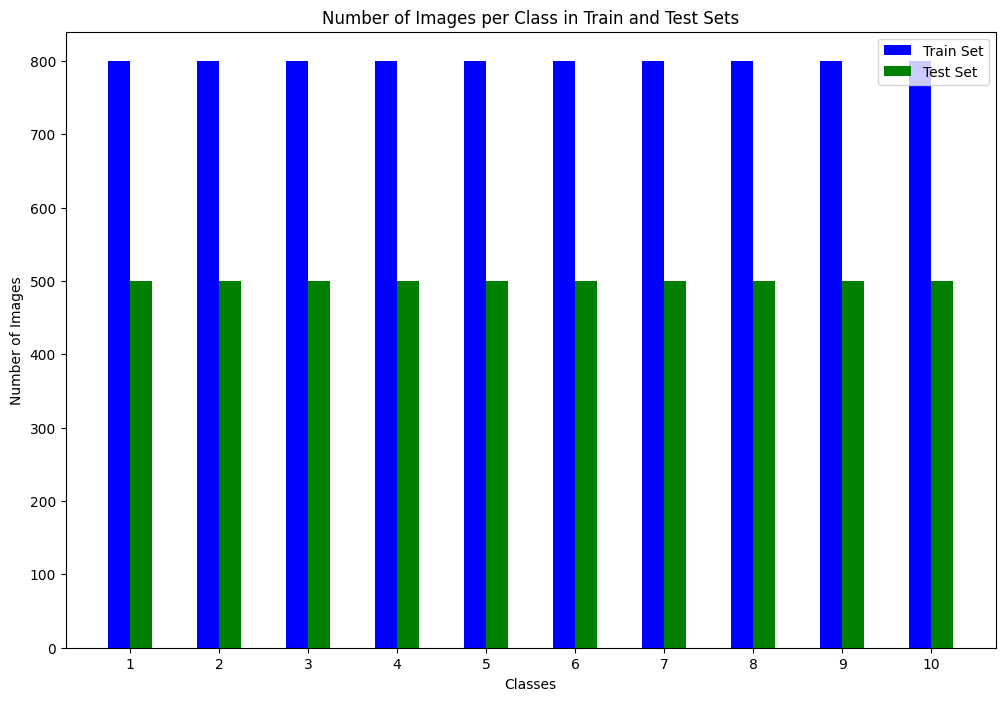

In [3]:
img_train_dir_path = 'images/imagebits/train/'
img_test_dir_path = 'images/imagebits/test/'
number_classes = {}

for i in range(1, 11):
    train_class_dir = os.path.join(img_train_dir_path, str(i))
    test_class_dir = os.path.join(img_test_dir_path, str(i))

    train_images = os.listdir(train_class_dir)
    test_images = os.listdir(test_class_dir)

    number_classes[i] = {'train_count': len(train_images), 'test_count': len(test_images)}

labels = list(number_classes.keys())
train_vals = []
test_vals = []

for v in number_classes.values():
    train_vals.append(v['train_count'])
    test_vals.append(v['test_count'])

x = np.arange(len(labels))
width = 0.25

fig = plt.subplots(figsize=(12, 8))
plt.bar(x - width/2, train_vals, width, label='Train Set', color='blue')
plt.bar(x + width/2, test_vals, width, label='Test Set', color='green')

plt.xlabel('Classes')
plt.ylabel('Number of Images')
plt.title('Number of Images per Class in Train and Test Sets')
plt.xticks(x, labels)
plt.legend()
plt.show()

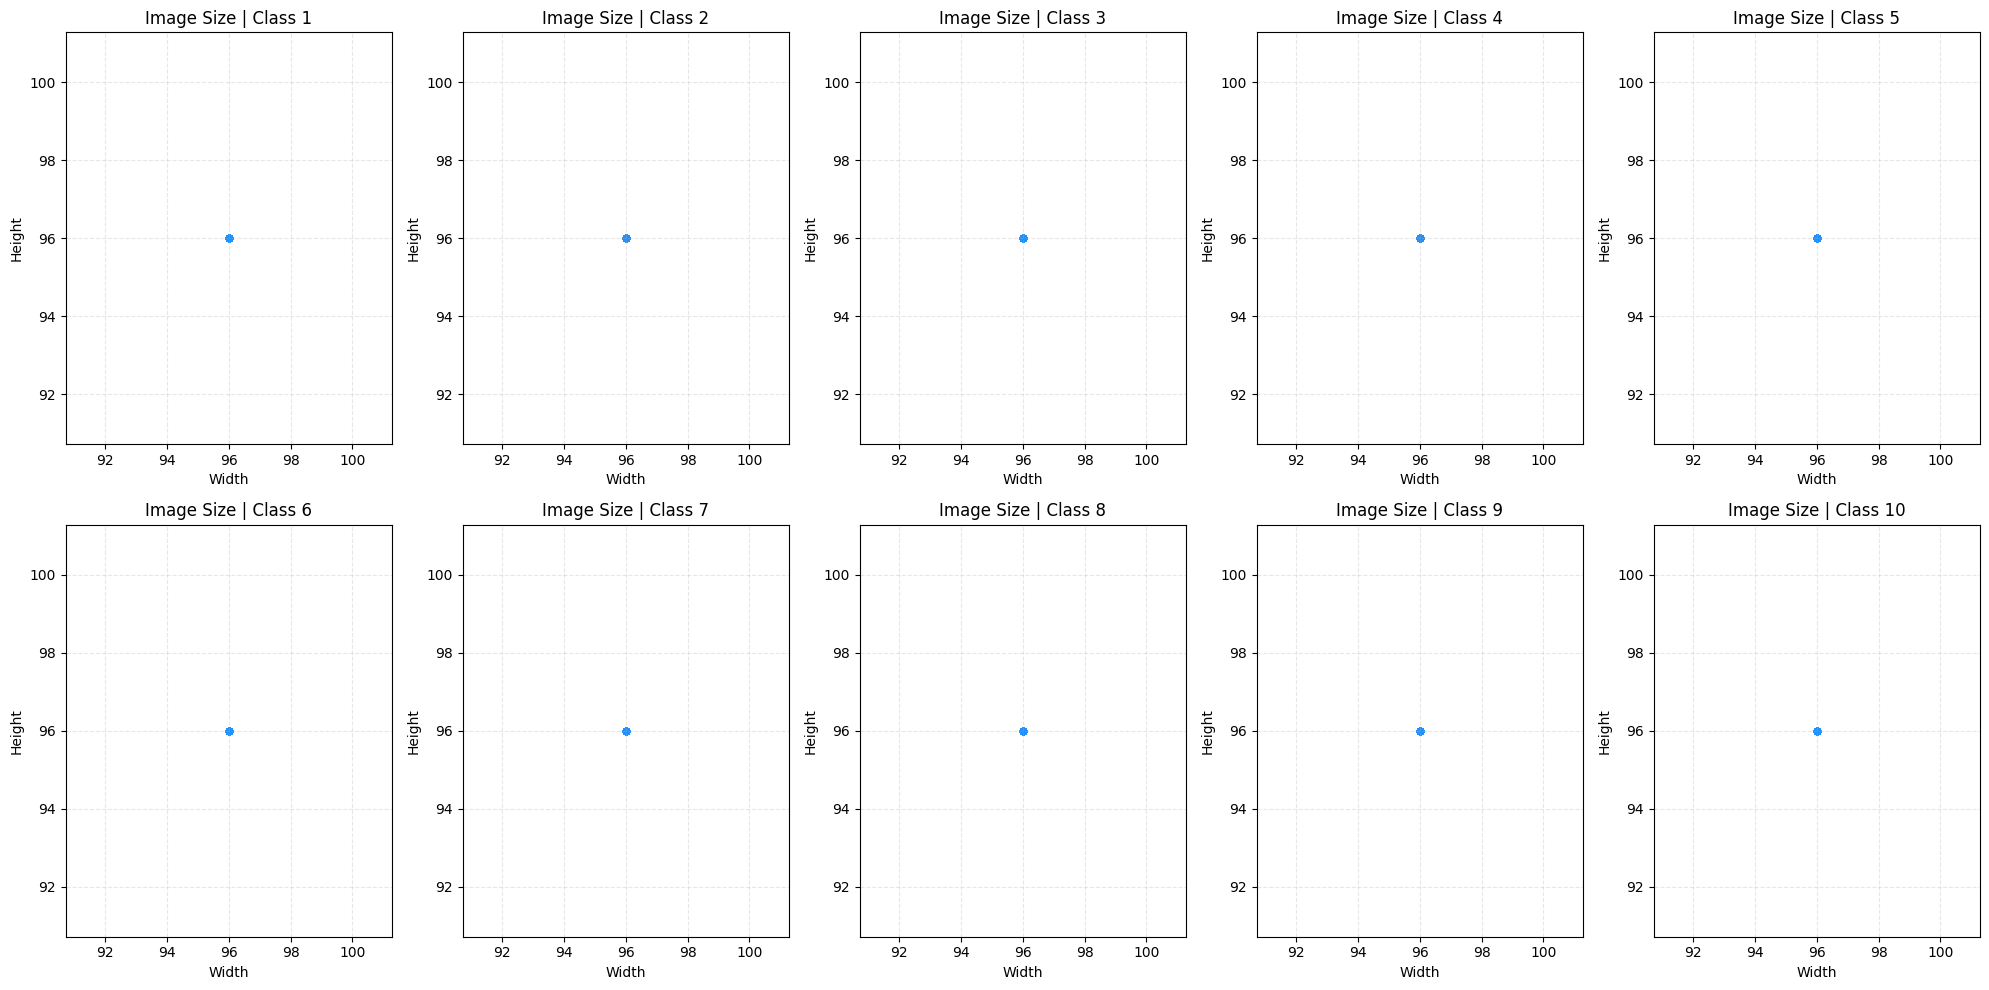

In [4]:
class_data = {}

for i in range(1, 11):
    class_dir = os.path.join(img_train_dir_path, str(i))
    images = os.listdir(class_dir)

    widths = []
    heights = []

    for img_name in images:
        if img_name.lower().endswith(('.png')):
            img_path = os.path.join(class_dir, img_name)
            with Image.open(img_path) as img:
                w, h = img.size
                widths.append(w)
                heights.append(h)

    class_data[i] = {'widths': widths, 'heights': heights}

fig, ax = plt.subplots(2, 5, figsize=(20, 10))

for idx, class_id in enumerate(range(1, 11)):
    weight = class_data[class_id]['widths']
    height = class_data[class_id]['heights']

    row_idx = idx // 5
    col_idx = idx % 5

    ax[row_idx, col_idx].scatter(weight, height, alpha=0.5, s=20, color='dodgerblue')
    ax[row_idx, col_idx].set_title(f'Image Size | Class {class_id}')
    ax[row_idx, col_idx].set_xlabel('Width')
    ax[row_idx, col_idx].set_ylabel('Height')
    ax[row_idx, col_idx].grid(True, linestyle='--', alpha=0.3)

plt.tight_layout()
plt.show()

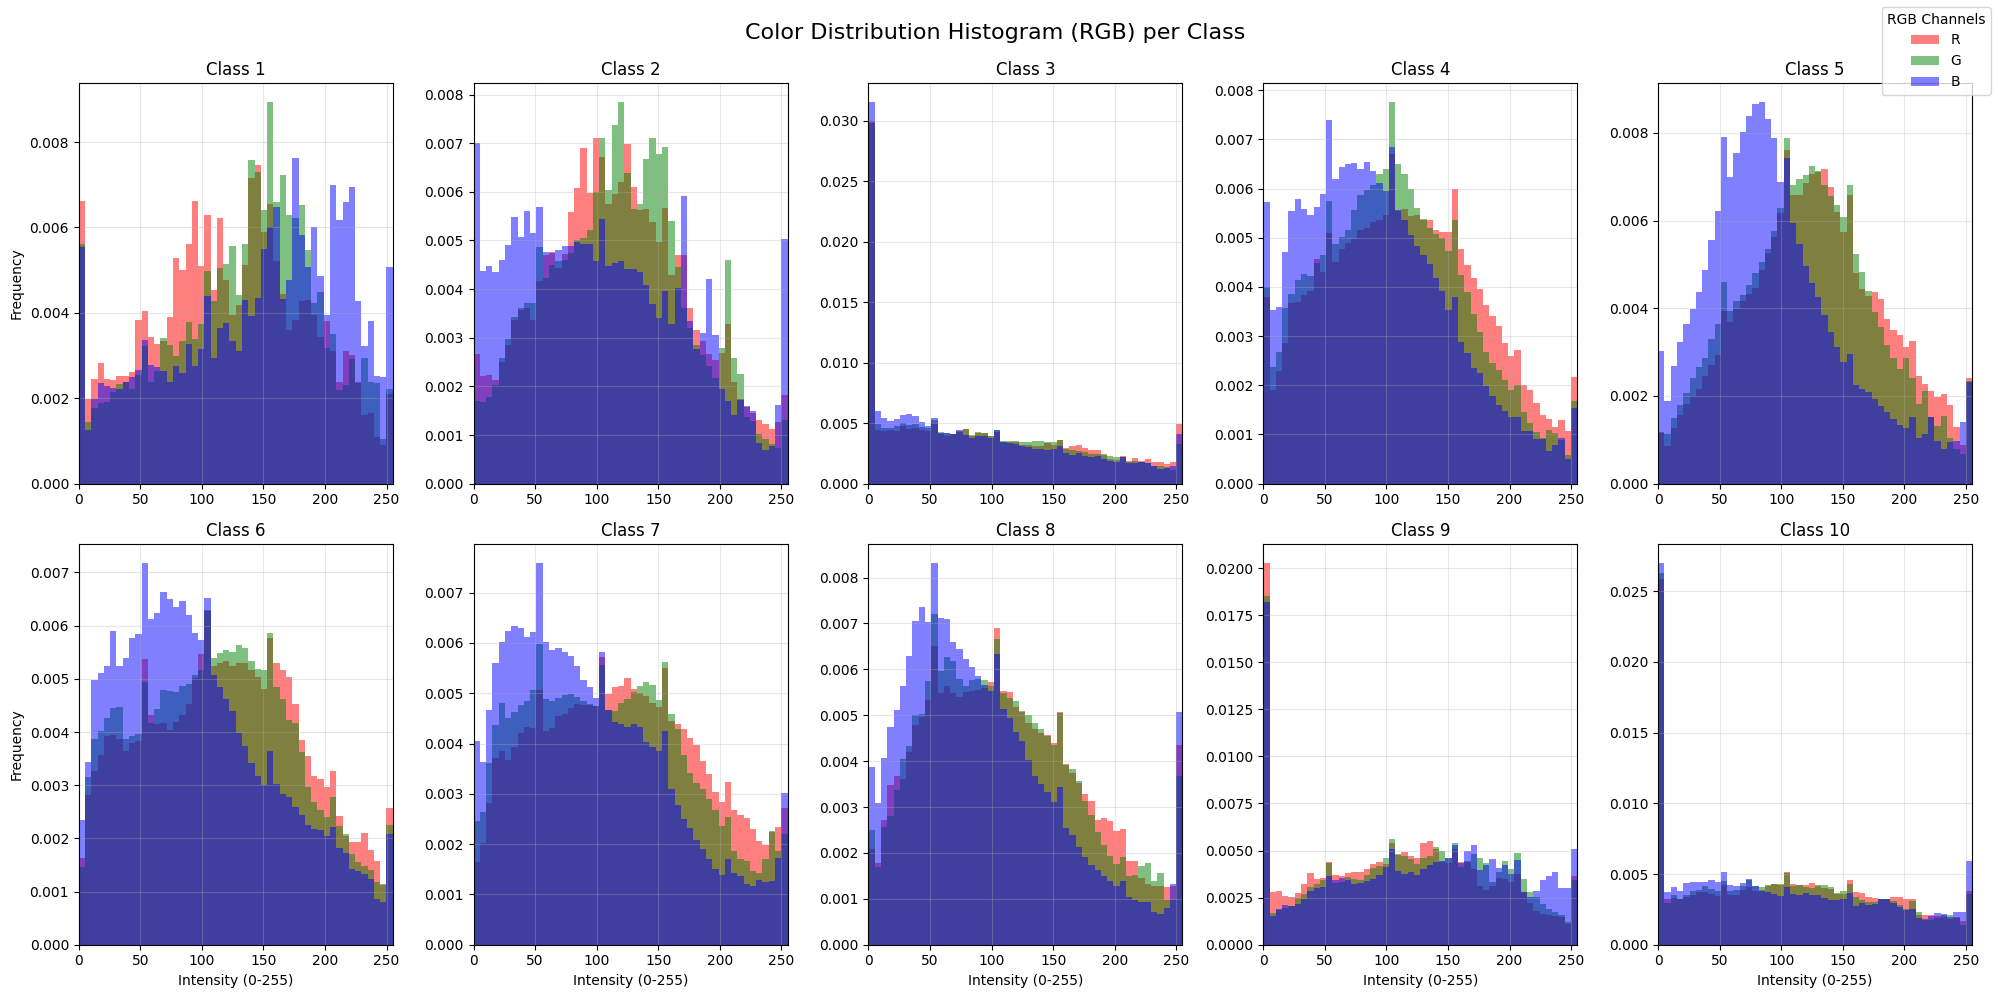

In [5]:
rgb_class = {}

for idx, class_id in enumerate(range(1, 11)):
    class_dir = os.path.join(img_train_dir_path, str(class_id))

    images = os.listdir(class_dir)
    if len(images) > 100:
        images = images[:100]

    all_reds = []
    all_greens = []
    all_blues = []

    for img_name in images:
        if img_name.lower().endswith(('.png')):
            img_path = os.path.join(class_dir, img_name)
            with Image.open(img_path).convert('RGB') as img:
                img_array = np.array(img)
                all_reds.extend(img_array[:, :, 0].flatten())
                all_greens.extend(img_array[:, :, 1].flatten())
                all_blues.extend(img_array[:, :, 2].flatten())

    rgb_class[class_id] = { 'red': all_reds, 'green': all_greens, 'blue': all_blues }


fig, ax = plt.subplots(nrows=2, ncols=5, figsize=(20, 10))

for idx, class_id in enumerate(range(1, 11)):
    red = rgb_class[class_id]["red"]
    green = rgb_class[class_id]["green"]
    blue = rgb_class[class_id]["blue"]

    row_idx = idx // 5
    col_idx = idx % 5

    ax[row_idx, col_idx].hist(red, bins=50, color='red', alpha=0.5, label='R', density=True)
    ax[row_idx, col_idx].hist(green, bins=50, color='green', alpha=0.5, label='G', density=True)
    ax[row_idx, col_idx].hist(blue, bins=50, color='blue', alpha=0.5, label='B', density=True)
    ax[row_idx, col_idx].set_title(f'Class {class_id}')
    ax[row_idx, col_idx].set_xlim(0, 255)

    if idx % 5 == 0:
        ax[row_idx, col_idx].set_ylabel('Frequency')
    if idx >= 5:
        ax[row_idx, col_idx].set_xlabel('Intensity (0-255)')

    ax[row_idx, col_idx].grid(True, alpha=0.3)

handles, labels = ax[row_idx, col_idx].get_legend_handles_labels()
fig.legend(handles, labels, loc='upper right', title="RGB Channels")

plt.suptitle("Color Distribution Histogram (RGB) per Class", fontsize=16)
plt.tight_layout()
plt.subplots_adjust(top=0.92)
plt.show()

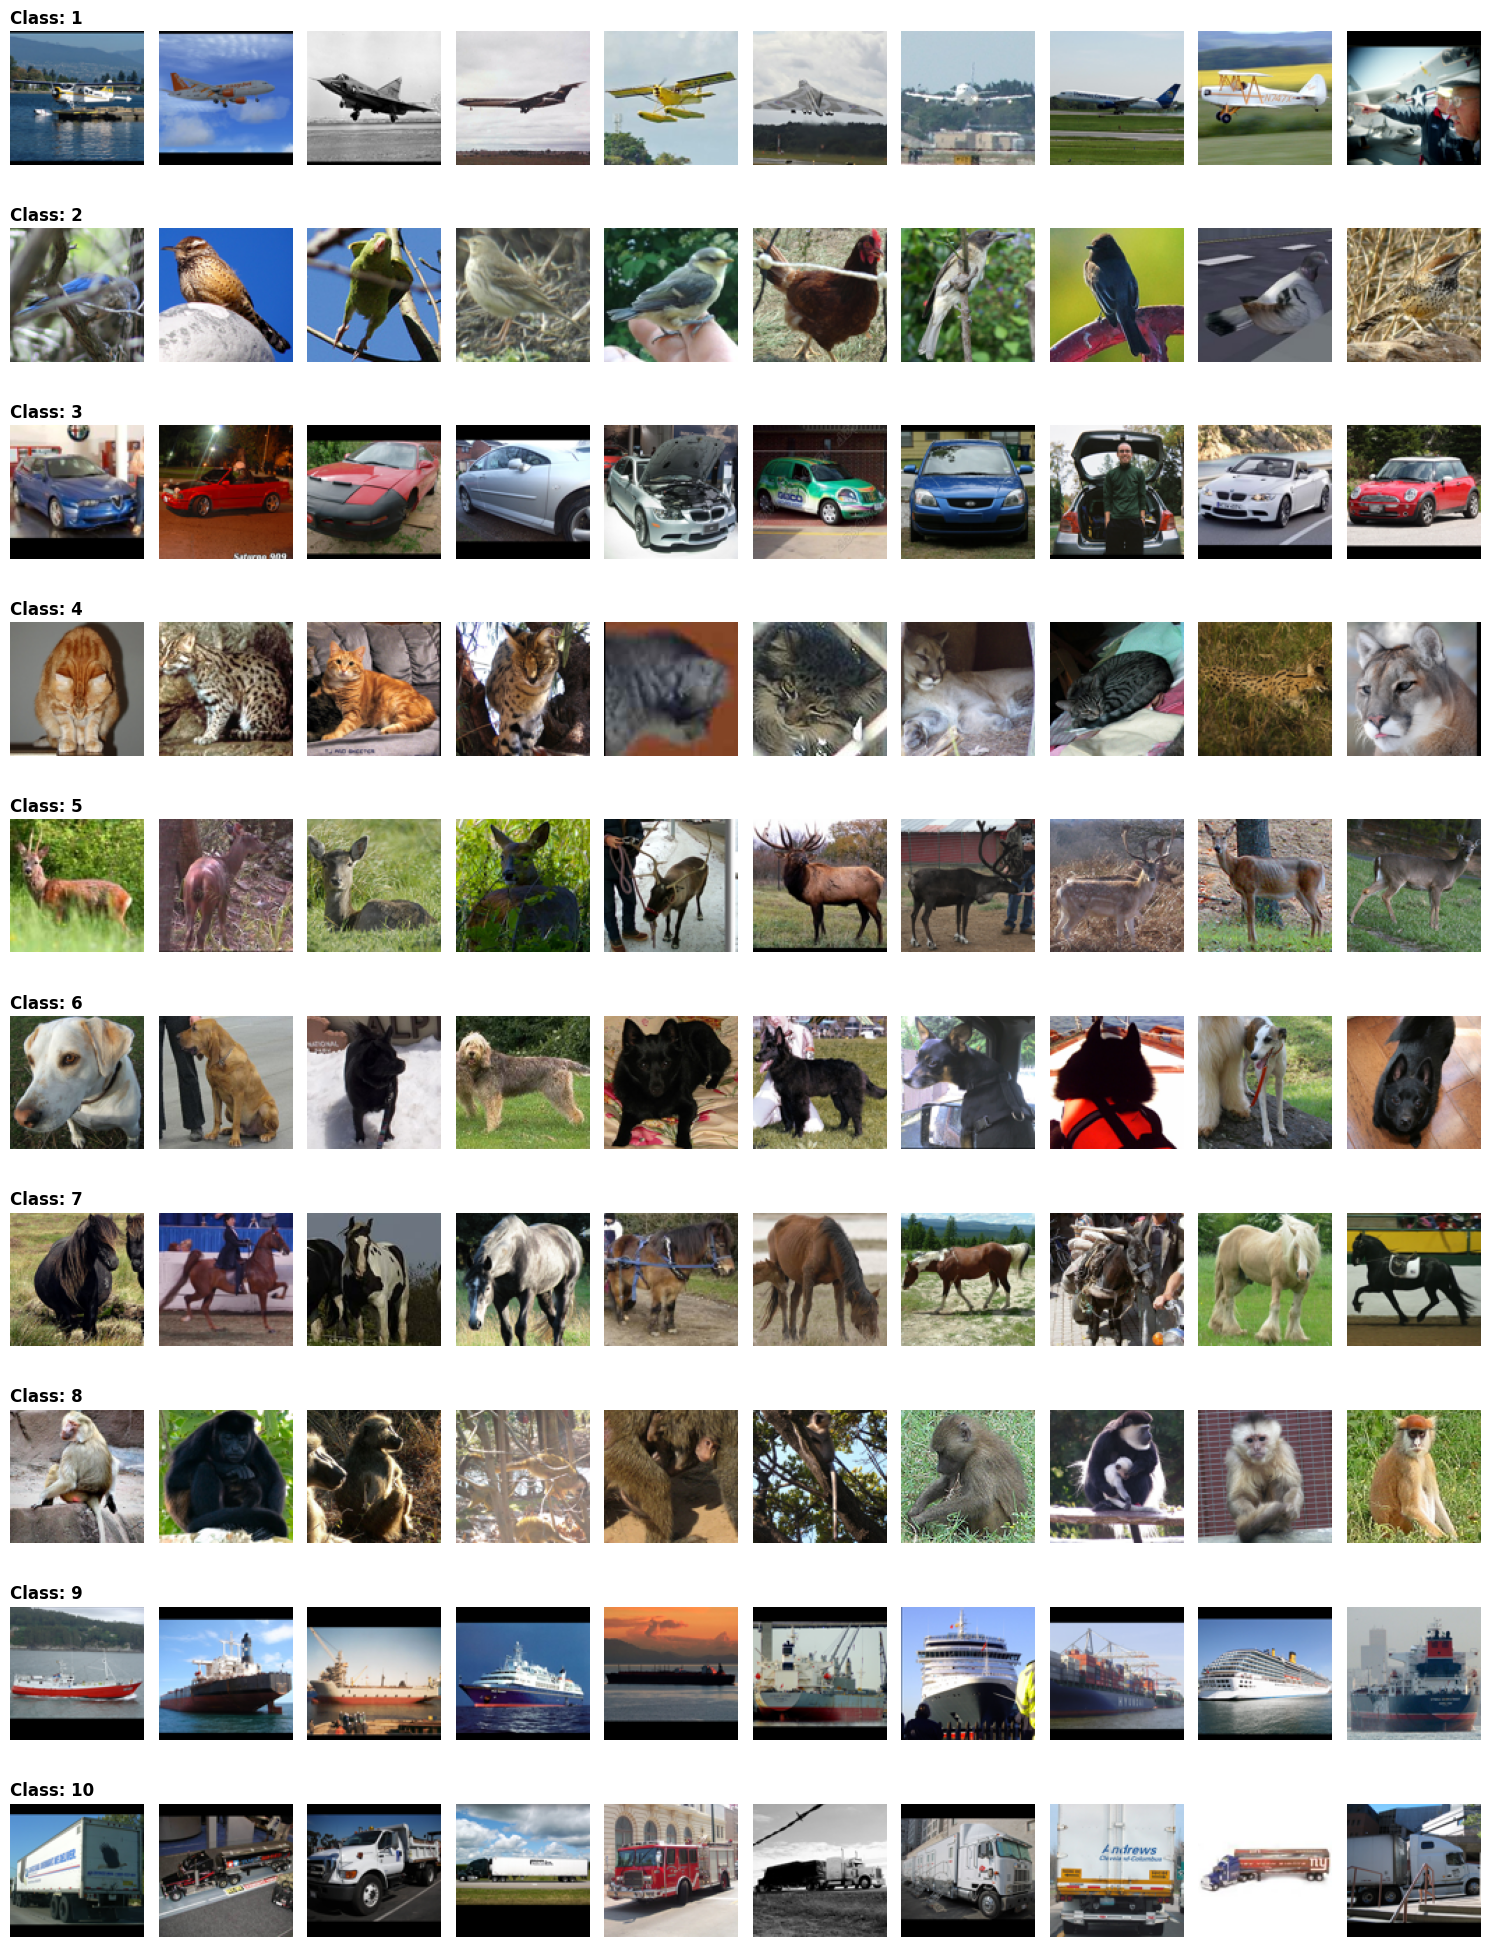

In [6]:
fig, ax = plt.subplots(10, 10, figsize=(15, 20))

for row_idx, class_id in enumerate(range(1, 11)):
    class_dir = os.path.join(img_train_dir_path, str(class_id))
    all_imgs = []
    for f in os.listdir(class_dir):
      if f.lower().endswith(('.png')):
        all_imgs.append(f)

    current_samples = random.sample(all_imgs, min(len(all_imgs), 10))
    for col_idx, img_name in enumerate(current_samples):
        img_path = os.path.join(class_dir, img_name)
        with Image.open(img_path) as img:
            ax[row_idx, col_idx].imshow(img)
            ax[row_idx, col_idx].axis('off')

            if col_idx == 0:
                ax[row_idx, col_idx].set_title(f'Class: {class_id}', fontsize=12, fontweight='bold', loc='left')

plt.tight_layout()
plt.show()

In [7]:
if torch.cuda.is_available():
  device = torch.device("cuda")
else:
  device = torch.device("cpu")

print(f"Running on device: {device}")

train_transform = transforms.Compose([
    transforms.Resize((96, 96)),
    transforms.ToTensor(),
    transforms.Normalize([0.5, 0.5, 0.5], [0.5, 0.5, 0.5])
])

train_transform_aug = transforms.Compose([
    transforms.Resize((96, 96)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(degrees=15),
    transforms.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2),
    transforms.RandomAffine(degrees=0, translate=(0.1, 0.1)),
    transforms.ToTensor(),
    transforms.Normalize([0.5, 0.5, 0.5], [0.5, 0.5, 0.5])
])

test_transform = transforms.Compose([
    transforms.Resize((96, 96)),
    transforms.ToTensor(),
    transforms.Normalize([0.5, 0.5, 0.5], [0.5, 0.5, 0.5])
])

train_images_aug = torchvision.datasets.ImageFolder(root=img_train_dir_path, transform=train_transform_aug)
train_images = torchvision.datasets.ImageFolder(root=img_train_dir_path, transform=train_transform)
test_images = torchvision.datasets.ImageFolder(root=img_test_dir_path, transform=test_transform)

print(f'Size of training labels {len(train_images.targets)}')
print(f'Size of test labels {len(test_images.targets)}')

Running on device: cuda
Size of training labels 8000
Size of test labels 5000


In [8]:
BATCH_SIZE_TRAIN = 64
BATCH_SIZE_TEST = 64
NO_WORKERS = 8
SHUFFLE_DATA = True

train_loader = torch.utils.data.DataLoader(train_images, batch_size=BATCH_SIZE_TRAIN, shuffle=SHUFFLE_DATA, num_workers=NO_WORKERS)
(batch_train_images, batch_train_labels) = next(iter(train_loader))

print(f'Shape of training images: {batch_train_images.size()}')
print(f'Shape of training labels: {batch_train_labels.size()}')

train_loader_aug = torch.utils.data.DataLoader(train_images_aug, batch_size=BATCH_SIZE_TRAIN, shuffle=SHUFFLE_DATA, num_workers=NO_WORKERS)
(batch_train_images_aug, batch_train_labels_aug) = next(iter(train_loader_aug))
print(f'Shape of augmented training images: {batch_train_images_aug.size()}')
print(f'Shape of augmented training labels: {batch_train_labels_aug.size()}')

Shape of training images: torch.Size([64, 3, 96, 96])
Shape of training labels: torch.Size([64])
Shape of augmented training images: torch.Size([64, 3, 96, 96])
Shape of augmented training labels: torch.Size([64])


In [9]:
test_loader = torch.utils.data.DataLoader(test_images, batch_size=BATCH_SIZE_TRAIN, shuffle=SHUFFLE_DATA, num_workers=NO_WORKERS)

def loopy_test_loader(dl):
    data_iter = iter(dl)

    while True:
        try:
            yield next(data_iter)
        except StopIteration:
            data_iter = iter(dl)
            yield next(data_iter)

(batch_test_images, batch_test_labels) = next(iter(test_loader))
print(f'Shape of test images: {batch_test_images.size()}')
print(f'Shape of test labels: {batch_test_labels.size()}')

Shape of test images: torch.Size([64, 3, 96, 96])
Shape of test labels: torch.Size([64])


In [10]:
def plot_losses(loss_list, steps, ct):
    if ct % 1000 == 0:
        display.clear_output(wait=True)

    display.display(plt.gcf())
    plt.plot(steps, loss_list, c='b')
    time.sleep(1.0)

def get_num_params(model):
    num_params = 0
    for params in model.parameters():
        num_params += params.shape.numel()

    return num_params

def top_k_accuracy(k, target, output):
    batch_size = target.size(0)

    _, pred = output.topk(k, 1, True, True)

    pred = pred.t()
    correct = pred.eq(target.to(device).view(1, -1).expand_as(pred))

    correct_k = correct[:k].view(-1).float().sum(0, keepdim=True)
    correct_k.mul_(100.0 / batch_size)

    return correct_k

In [11]:
import torch.nn as nn

class MLP(nn.Module):
    def __init__(self, img_size = 96, hidden_size=512, out_size=256, num_classes=10):
        super(MLP, self).__init__()

        self.in_size = 3 * img_size * img_size

        self.fc1 = nn.Linear(self.in_size, hidden_size)
        self.fc2 = nn.Linear(hidden_size, out_size)
        self.fc3 = nn.Linear(out_size, num_classes)

        self.relu = nn.ReLU(inplace=True)
        self.dropout = nn.Dropout(p=0.5)

    def forward(self, x):
        x = x.view(x.size(0), -1)

        x = self.relu(self.fc1(x))
        x = self.dropout(x)

        x = self.relu(self.fc2(x))
        x = self.dropout(x)

        x = self.fc3(x)

        return x

In [26]:
import torch
import torch.nn as nn

class MiniVGG(nn.Module):
    def __init__(self, num_classes=10, in_size=512, hidden_size1=1024, hidden_size2=1024, use_batch_norm=False, dropout_val=0.5):
        super(MiniVGG, self).__init__()

        self.conv1 = nn.Conv2d(in_channels=3, out_channels=64, kernel_size=3, padding=1)
        if use_batch_norm:
            self.bn1 = nn.BatchNorm2d(64)
        else:
            self.bn1 = nn.Identity()

        self.conv2 = nn.Conv2d(in_channels=64, out_channels=64, kernel_size=3, padding=1)
        if use_batch_norm:
            self.bn2 = nn.BatchNorm2d(64)
        else:
            self.bn2 = nn.Identity()

        self.conv3 = nn.Conv2d(in_channels=64, out_channels=128, kernel_size=3, padding=1)
        if use_batch_norm:
            self.bn3 = nn.BatchNorm2d(128)
        else:
            self.bn3 = nn.Identity()

        self.conv4 = nn.Conv2d(in_channels=128, out_channels=128, kernel_size=3, padding=1)
        if use_batch_norm:
            self.bn4 = nn.BatchNorm2d(128)
        else:
            self.bn4 = nn.Identity()

        self.conv5 = nn.Conv2d(in_channels=128, out_channels=256, kernel_size=3, padding=1)
        if use_batch_norm:
            self.bn5 = nn.BatchNorm2d(256)
        else:
            self.bn5 = nn.Identity()

        self.conv6 = nn.Conv2d(in_channels=256, out_channels=256, kernel_size=3, padding=1)
        if use_batch_norm:
            self.bn6 = nn.BatchNorm2d(256)
        else:
            self.bn6 = nn.Identity()

        self.conv7 = nn.Conv2d(in_channels=256, out_channels=512, kernel_size=3, padding=1)
        if use_batch_norm:
            self.bn7 = nn.BatchNorm2d(512)
        else:
            self.bn7 = nn.Identity()

        self.conv8 = nn.Conv2d(in_channels=512, out_channels=512, kernel_size=3, padding=1)
        if use_batch_norm:
            self.bn8 = nn.BatchNorm2d(512)
        else:
            self.bn8 = nn.Identity()

        self.pool = nn.MaxPool2d(kernel_size=2, stride=2)
        self.avgpool = nn.AdaptiveAvgPool2d((7, 7))

        flatten_size = in_size * 7 * 7

        self.fc1 = nn.Linear(in_features=flatten_size, out_features=hidden_size1)
        self.fc2 = nn.Linear(in_features=hidden_size1, out_features=hidden_size2)
        self.fc3 = nn.Linear(in_features=hidden_size2, out_features=num_classes)

        self.relu = nn.ReLU(inplace=True)
        self.dropout = nn.Dropout(p=dropout_val)

    def forward(self, x):
        x = self.relu(self.bn1(self.conv1(x)))
        x = self.relu(self.bn2(self.conv2(x)))
        x = self.pool(x)

        x = self.relu(self.bn3(self.conv3(x)))
        x = self.relu(self.bn4(self.conv4(x)))
        x = self.pool(x)

        x = self.relu(self.bn5(self.conv5(x)))
        x = self.relu(self.bn6(self.conv6(x)))
        x = self.pool(x)

        x = self.relu(self.bn7(self.conv7(x)))
        x = self.relu(self.bn8(self.conv8(x)))
        x = self.pool(x)

        x = self.avgpool(x)
        x = x.view(x.size(0), -1)

        x = self.relu(self.fc1(x))
        x = self.dropout(x)

        x = self.relu(self.fc2(x))
        x = self.dropout(x)

        x = self.fc3(x)

        return x

In [13]:
EPOCHS = 50
TRAIN_ITERS = 100e3
REPORT_TRAIN_EVERY = 100
PLOT_EVERY = 100
REPORT_TEST_EVERY = 200
TEST_ITERS = 100

criterion = nn.CrossEntropyLoss()

def train_engine(net, train_data_loader, optimizer, scheduler, num_epochs=35, name="Experiment"):
    history = {
        'train_loss': [], 'train_acc': [], 'train_steps': [],
        'val_loss': [], 'val_acc': [], 'val_steps': []
    }

    train_iter = 0
    running_loss = 0.0
    running_acc = 0.0

    test_data_provider = loopy_test_loader(test_loader)

    net.train()

    for epoch in range(num_epochs):
        for i, data in enumerate(train_data_loader, 0):

            inputs, labels = data[0].to(device), data[1].to(device)
            optimizer.zero_grad()
            outputs = net(inputs)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()

            running_loss += loss.item()
            running_acc += top_k_accuracy(1, labels, outputs).item()

            if train_iter % REPORT_TRAIN_EVERY == REPORT_TRAIN_EVERY - 1:
                train_loss = running_loss / REPORT_TRAIN_EVERY
                train_acc = running_acc / REPORT_TRAIN_EVERY

                print(f'[{name}] [Ep: {epoch+1}, Step: {train_iter}] Train Loss: {train_loss:.5f}, Acc: {train_acc:.2f}%')

                history['train_loss'].append(train_loss)
                history['train_acc'].append(train_acc)
                history['train_steps'].append(train_iter)

                running_loss = 0.0
                running_acc = 0.0

            if train_iter % REPORT_TEST_EVERY == 0:
                net.eval()
                with torch.no_grad():
                    test_iter = 0
                    test_loss_accum = 0.0
                    test_acc_accum = 0.0

                    while test_iter < TEST_ITERS:
                        try:
                            test_data = next(test_data_provider)
                        except StopIteration:
                            test_data_provider = loopy_test_loader(test_loader)
                            test_data = next(test_data_provider)

                        t_in, t_lbl = test_data[0].to(device), test_data[1].to(device)
                        t_out = net(t_in)

                        test_loss_accum += criterion(t_out, t_lbl).item()
                        test_acc_accum += top_k_accuracy(1, t_lbl, t_out).item()
                        test_iter += 1

                    avg_test_loss = test_loss_accum / TEST_ITERS
                    avg_test_acc = test_acc_accum / TEST_ITERS

                    print(f'>>> [{name} Val] Loss: {avg_test_loss:.5f}, Acc: {avg_test_acc:.2f}%')

                    history['val_loss'].append(avg_test_loss)
                    history['val_acc'].append(avg_test_acc)
                    history['val_steps'].append(train_iter)

                net.train()

            train_iter += 1

        scheduler.step()

    print(f"Finished: {name}")
    return history

In [28]:
experiments = [
    {
        "name": "Balanced_Adam_NoAug",
        "hidden": 1024,
        "out": 256,
        "opt": "adam",
        "lr": 0.0001,
        "wd": 1e-3,
        "augmentation": False
    },
    {
        "name": "Classic_SGD_NoAug",
        "hidden": 512,
        "out": 128,
        "opt": "sgd",
        "lr": 0.05,
        "wd": 5e-4,
        "augmentation": False
    },
    {
        "name": "Wide_Slow_Adam_NoAug",
        "hidden": 2048,
        "out": 512,
        "opt": "adam",
        "lr": 1e-5,
        "wd": 1e-4,
        "augmentation": False
    },
    {
        "name": "LongRun_Adam",
        "hidden": 1024,
        "out": 256,
        "opt": "adam",
        "lr": 0.0001,
        "wd": 0,
        "augmentation": True
    },
    {
        "name": "Patience_SGD",
        "hidden": 2048,
        "out": 512,
        "opt": "sgd",
        "lr": 0.01,
        "wd": 1e-5,
        "augmentation": True
    },
    {
        "name": "Aggressive_Adam",
        "hidden": 4096,
        "out": 1024,
        "opt": "adam",
        "lr": 0.00005,
        "wd": 1e-5,
        "augmentation": True
    }
]

results_table = []
best_acc = 0.0
best_model_state = None
best_model_name = ""
best_config_hidden = 0
best_config_out = 0

for exp in experiments:
    print(f"\n{'='*60}")
    print(f"Starting: {exp['name']}")
    print(f"{'='*60}")

    net = MLP(img_size=96, hidden_size=exp['hidden'], out_size=exp['out'], num_classes=10).to(device)

    if exp['opt'] == 'adam':
        optimizer = optim.Adam(net.parameters(), lr=exp['lr'], weight_decay=exp['wd'])
    elif exp['opt'] == 'sgd':
        optimizer = optim.SGD(net.parameters(), lr=exp['lr'], momentum=0.9, weight_decay=exp['wd'])

    if exp['augmentation']:
        loader = train_loader_aug
        num_epochs = 50
    else:
        loader = train_loader
        num_epochs = 25

    scheduler = optim.lr_scheduler.MultiStepLR(optimizer, milestones=[2000, 3000], gamma=0.1)

    hist = train_engine(net, loader, optimizer, scheduler, num_epochs=num_epochs, name=exp['name'])

    plt.figure(figsize=(10, 4))

    plt.subplot(1, 2, 1)
    plt.plot(hist['train_loss'], label='Train Loss', linestyle='--')
    plt.plot(hist['val_loss'], label='Test Loss', linewidth=2)
    plt.title(f"{exp['name']} - Loss")
    plt.legend()
    plt.grid()

    plt.subplot(1, 2, 2)
    plt.plot(hist['train_acc'], label='Train Acc', linestyle='--')
    plt.plot(hist['val_acc'], label='Test Acc', linewidth=2)
    plt.title(f"{exp['name']} - Acc")
    plt.legend()
    plt.grid()

    plt.show()

    final_acc = hist['val_acc'][-1]
    final_loss = hist['val_loss'][-1]
    if torch.is_tensor(final_acc):
        final_acc = final_acc.item()

    results_table.append({
        "Model": exp['name'],
        "Hidden Size": exp['hidden'],
        "Out Size": exp['out'],
        "Augmentation": exp['augmentation'],
        "Optimizator": exp['opt'],
        "LR": exp['lr'],
        "Final Val Acc": f"{final_acc:.2f}%",
        "Final Val Loss": f"{final_loss:.4f}"
    })

    if final_acc > best_acc:
        best_acc = final_acc
        best_model_name = exp['name']
        best_config_hidden = exp['hidden']
        best_config_out = exp['out']
        best_model_state = copy.deepcopy(net.state_dict())


Starting: Balanced_Adam_NoAug
>>> [Balanced_Adam_NoAug Val] Loss: 2.25933, Acc: 18.83%


KeyboardInterrupt: 


Final results:


,Model,Hidden Size,Out Size,Augmentation,Optimizator,LR,Final Val Acc,Final Val Loss
0,Balanced_Adam_NoAug,1024,256,False,adam,0.00010,45.30%,1.6141
1,Classic_SGD_NoAug,512,128,False,sgd,0.05000,10.28%,2.3041
2,Wide_Slow_Adam_NoAug,2048,512,False,adam,0.00001,44.78%,1.5284
3,LongRun_Adam,1024,256,True,adam,0.00010,42.05%,1.6241
4,Patience_SGD,2048,512,True,sgd,0.01000,31.89%,1.8588
5,Aggressive_Adam,4096,1024,True,adam,0.00005,43.92%,1.5750



Confusion Matrix for: Balanced_Adam_NoAug (Acc: 45.30%)


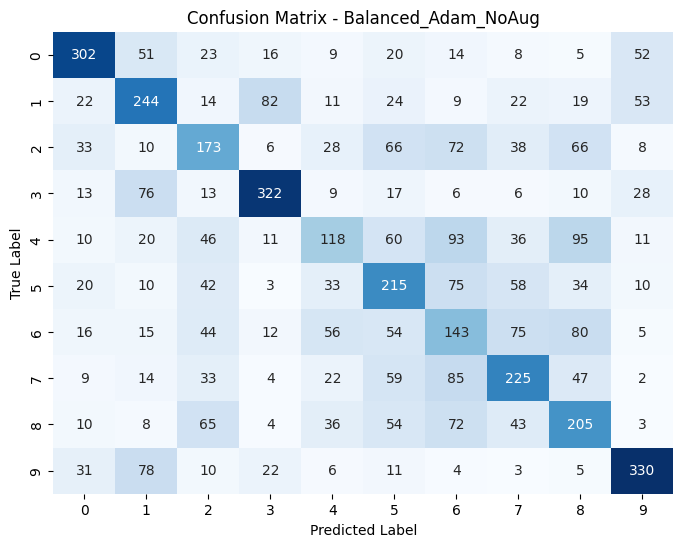


Best model: Balanced_Adam_NoAug with 45.30% accuracy


In [22]:
print("\nFinal results:")
df = pd.DataFrame(results_table)
display.display(df)

print(f"\nConfusion Matrix for: {best_model_name} (Acc: {best_acc:.2f}%)")

final_net = MLP(img_size=96, hidden_size=best_config_hidden, out_size=best_config_out, num_classes=10).to(device)
final_net.load_state_dict(best_model_state)
final_net.eval()

all_preds = []
all_labels = []

final_test_loader = torch.utils.data.DataLoader(test_images, batch_size=64, shuffle=False, num_workers=2)

with torch.no_grad():
    for inputs, labels in final_test_loader:
        inputs = inputs.to(device)
        outputs = final_net(inputs)
        _, preds = torch.max(outputs, 1)
        all_preds.extend(preds.cpu().numpy())
        all_labels.extend(labels.numpy())

cm = confusion_matrix(all_labels, all_preds)
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False)
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.title(f'Confusion Matrix - {best_model_name}')
plt.show()

print(f"\nBest model: {best_model_name} with {best_acc:.2f}% accuracy")


Starting: VGG_Heavy_Adam
>>> [VGG_Heavy_Adam Val] Loss: 2.30276, Acc: 10.00%
[VGG_Heavy_Adam] [Ep: 1, Step: 99] Train Loss: 1.95023, Acc: 27.39%
[VGG_Heavy_Adam] [Ep: 2, Step: 199] Train Loss: 1.54233, Acc: 40.19%
>>> [VGG_Heavy_Adam Val] Loss: 1.42217, Acc: 43.98%
[VGG_Heavy_Adam] [Ep: 3, Step: 299] Train Loss: 1.37102, Acc: 48.06%
[VGG_Heavy_Adam] [Ep: 4, Step: 399] Train Loss: 1.21042, Acc: 55.14%
>>> [VGG_Heavy_Adam Val] Loss: 1.30442, Acc: 54.00%
[VGG_Heavy_Adam] [Ep: 4, Step: 499] Train Loss: 1.10622, Acc: 59.77%
[VGG_Heavy_Adam] [Ep: 5, Step: 599] Train Loss: 0.97076, Acc: 64.92%
>>> [VGG_Heavy_Adam Val] Loss: 1.26065, Acc: 55.81%
[VGG_Heavy_Adam] [Ep: 6, Step: 699] Train Loss: 0.89422, Acc: 67.97%
[VGG_Heavy_Adam] [Ep: 7, Step: 799] Train Loss: 0.81104, Acc: 70.62%
>>> [VGG_Heavy_Adam Val] Loss: 1.00990, Acc: 64.73%
[VGG_Heavy_Adam] [Ep: 8, Step: 899] Train Loss: 0.76728, Acc: 71.98%
[VGG_Heavy_Adam] [Ep: 8, Step: 999] Train Loss: 0.70599, Acc: 75.31%
>>> [VGG_Heavy_Adam Val] 

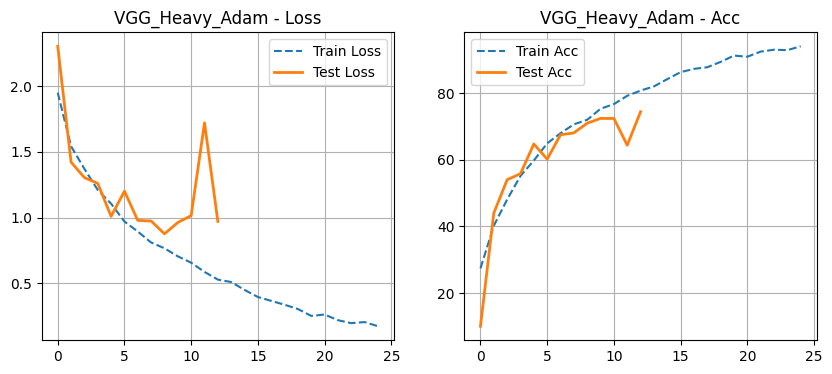


Starting: 2_VGG_Heavy_SGD
>>> [2_VGG_Heavy_SGD Val] Loss: 2.30265, Acc: 10.03%
[2_VGG_Heavy_SGD] [Ep: 1, Step: 99] Train Loss: 1.82548, Acc: 29.66%
[2_VGG_Heavy_SGD] [Ep: 2, Step: 199] Train Loss: 1.55756, Acc: 40.09%
>>> [2_VGG_Heavy_SGD Val] Loss: 1.56910, Acc: 40.00%
[2_VGG_Heavy_SGD] [Ep: 3, Step: 299] Train Loss: 1.40675, Acc: 47.75%
[2_VGG_Heavy_SGD] [Ep: 4, Step: 399] Train Loss: 1.30554, Acc: 51.53%
>>> [2_VGG_Heavy_SGD Val] Loss: 1.70334, Acc: 42.89%
[2_VGG_Heavy_SGD] [Ep: 4, Step: 499] Train Loss: 1.21546, Acc: 56.34%
[2_VGG_Heavy_SGD] [Ep: 5, Step: 599] Train Loss: 1.12736, Acc: 60.16%
>>> [2_VGG_Heavy_SGD Val] Loss: 1.48983, Acc: 52.58%
[2_VGG_Heavy_SGD] [Ep: 6, Step: 699] Train Loss: 1.07118, Acc: 61.33%
[2_VGG_Heavy_SGD] [Ep: 7, Step: 799] Train Loss: 0.99636, Acc: 65.02%
>>> [2_VGG_Heavy_SGD Val] Loss: 1.06664, Acc: 61.91%
[2_VGG_Heavy_SGD] [Ep: 8, Step: 899] Train Loss: 0.95337, Acc: 66.97%
[2_VGG_Heavy_SGD] [Ep: 8, Step: 999] Train Loss: 0.88350, Acc: 68.45%
>>> [2_VG

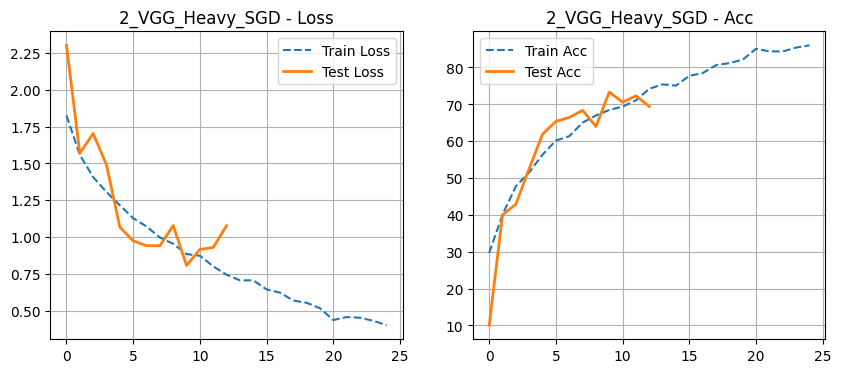


Starting: VGG_Medium_Adam
>>> [VGG_Medium_Adam Val] Loss: 2.30281, Acc: 10.03%
[VGG_Medium_Adam] [Ep: 1, Step: 99] Train Loss: 1.90209, Acc: 27.45%
[VGG_Medium_Adam] [Ep: 2, Step: 199] Train Loss: 1.51968, Acc: 41.55%
>>> [VGG_Medium_Adam Val] Loss: 1.37051, Acc: 49.44%
[VGG_Medium_Adam] [Ep: 3, Step: 299] Train Loss: 1.37867, Acc: 48.70%
[VGG_Medium_Adam] [Ep: 4, Step: 399] Train Loss: 1.21043, Acc: 55.72%
>>> [VGG_Medium_Adam Val] Loss: 1.18060, Acc: 57.39%
[VGG_Medium_Adam] [Ep: 4, Step: 499] Train Loss: 1.10059, Acc: 59.98%
[VGG_Medium_Adam] [Ep: 5, Step: 599] Train Loss: 0.97718, Acc: 65.02%
>>> [VGG_Medium_Adam Val] Loss: 1.05514, Acc: 62.44%
[VGG_Medium_Adam] [Ep: 6, Step: 699] Train Loss: 0.90472, Acc: 67.61%
[VGG_Medium_Adam] [Ep: 7, Step: 799] Train Loss: 0.81205, Acc: 70.92%
>>> [VGG_Medium_Adam Val] Loss: 0.98569, Acc: 64.77%
[VGG_Medium_Adam] [Ep: 8, Step: 899] Train Loss: 0.76161, Acc: 72.86%
[VGG_Medium_Adam] [Ep: 8, Step: 999] Train Loss: 0.69489, Acc: 75.16%
>>> [VGG_

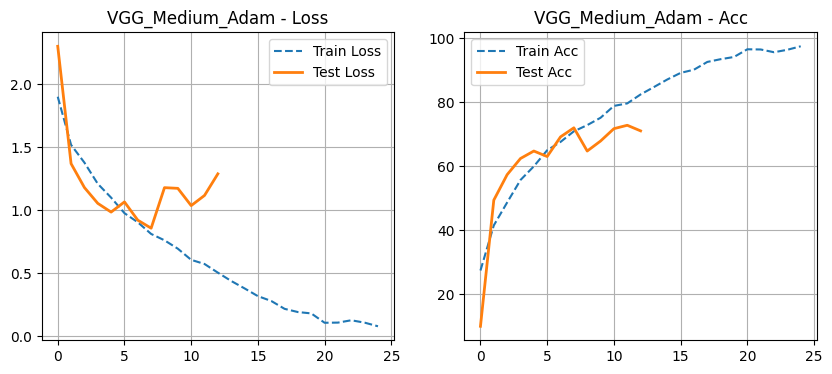


Starting: VGG_FullPower_Adam
>>> [VGG_FullPower_Adam Val] Loss: 2.30325, Acc: 10.06%
[VGG_FullPower_Adam] [Ep: 1, Step: 99] Train Loss: 2.61390, Acc: 17.38%
[VGG_FullPower_Adam] [Ep: 2, Step: 199] Train Loss: 1.91027, Acc: 26.86%
>>> [VGG_FullPower_Adam Val] Loss: 1.74742, Acc: 29.95%
[VGG_FullPower_Adam] [Ep: 3, Step: 299] Train Loss: 1.77692, Acc: 30.30%
[VGG_FullPower_Adam] [Ep: 4, Step: 399] Train Loss: 1.72937, Acc: 32.59%
>>> [VGG_FullPower_Adam Val] Loss: 1.57379, Acc: 38.97%
[VGG_FullPower_Adam] [Ep: 4, Step: 499] Train Loss: 1.67010, Acc: 32.88%
[VGG_FullPower_Adam] [Ep: 5, Step: 599] Train Loss: 1.63017, Acc: 35.61%
>>> [VGG_FullPower_Adam Val] Loss: 1.55920, Acc: 39.45%
[VGG_FullPower_Adam] [Ep: 6, Step: 699] Train Loss: 1.59569, Acc: 36.62%
[VGG_FullPower_Adam] [Ep: 7, Step: 799] Train Loss: 1.56013, Acc: 38.86%
>>> [VGG_FullPower_Adam Val] Loss: 1.44265, Acc: 44.97%
[VGG_FullPower_Adam] [Ep: 8, Step: 899] Train Loss: 1.53658, Acc: 40.48%
[VGG_FullPower_Adam] [Ep: 8, Step:

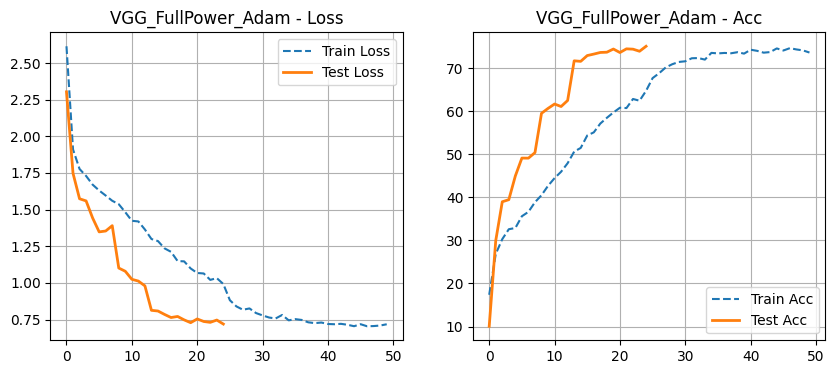


Starting: VGG_Classic_SGD_Aug
>>> [VGG_Classic_SGD_Aug Val] Loss: 2.30269, Acc: 10.11%
[VGG_Classic_SGD_Aug] [Ep: 1, Step: 99] Train Loss: 1.94380, Acc: 25.33%
[VGG_Classic_SGD_Aug] [Ep: 2, Step: 199] Train Loss: 1.70478, Acc: 33.52%
>>> [VGG_Classic_SGD_Aug Val] Loss: 1.53254, Acc: 38.94%
[VGG_Classic_SGD_Aug] [Ep: 3, Step: 299] Train Loss: 1.57090, Acc: 38.77%
[VGG_Classic_SGD_Aug] [Ep: 4, Step: 399] Train Loss: 1.47408, Acc: 43.97%
>>> [VGG_Classic_SGD_Aug Val] Loss: 1.55694, Acc: 42.91%
[VGG_Classic_SGD_Aug] [Ep: 4, Step: 499] Train Loss: 1.40026, Acc: 47.53%


KeyboardInterrupt: 

In [30]:
experiments = [
    {
        "name": "VGG_Heavy_Adam",
        "input": 512,
        "hidden1": 4096,
        "hidden2": 1024,
        "opt": "adam",
        "lr": 0.0001,
        "wd": 1e-4,
        "batch_norm": True,
        "dropout_val": 0.5,
        "augmentation": False
    },
    {
        "name": "2_VGG_Heavy_SGD",
        "input": 512,
        "hidden1": 2048,
        "hidden2": 2048,
        "opt": "sgd",
        "lr": 0.01,
        "momentum": 0.9,
        "wd": 5e-4,
        "batch_norm": True,
        "dropout_val": 0.4,
        "augmentation": False
    },
    {
        "name": "VGG_Medium_Adam",
        "input": 512,
        "hidden1": 2048,
        "hidden2": 512,
        "opt": "adam",
        "lr": 0.00005,
        "wd": 1e-5,
        "batch_norm": True,
        "dropout_val": 0.5,
        "augmentation": False
    }, {
        "name": "VGG_FullPower_Adam",
        "input": 512,
        "hidden1": 4096,
        "hidden2": 4096,
        "opt": "adam",
        "lr": 0.0003,
        "wd": 1e-5,
        "batch_norm": True,
        "dropout_val": 0.5,
        "augmentation": True
    },
    {
        "name": "VGG_Classic_SGD_Aug",
        "input": 512,
        "hidden1": 2048,
        "hidden2": 1024,
        "opt": "sgd",
        "lr": 0.01,
        "momentum": 0.9,
        "wd": 1e-4,
        "batch_norm": True,
        "dropout_val": 0.4,
        "augmentation": True
    },
    {
        "name": "VGG_SlowBurn_Adam",
        "input": 512,
        "hidden1": 2048,
        "hidden2": 512,
        "opt": "adam",
        "lr": 0.00001,
        "wd": 0,
        "batch_norm": True,
        "dropout_val": 0.3,
        "augmentation": True
    }

]

results_table = []
best_acc = 0.0
best_model_state = None
best_model_name = ""
best_config = {}

for exp in experiments:
    print(f"\n{'='*60}")
    print(f"Starting: {exp['name']}")
    print(f"{'='*60}")

    net = MiniVGG(num_classes=10, in_size=exp['input'], hidden_size1=exp['hidden1'], hidden_size2=exp['hidden2'],
                  use_batch_norm=exp['batch_norm'], dropout_val=exp['dropout_val']).to(device)

    if exp['augmentation']:
        loader = train_loader_aug
        num_epochs = 40
    else:
        loader = train_loader
        num_epochs = 20

    if exp['opt'] == 'sgd':
        optimizer = optim.SGD(net.parameters(), lr=exp['lr'], momentum=exp['momentum'], weight_decay=exp['wd'])
    elif exp['opt'] == 'adam':
        optimizer = optim.Adam(net.parameters(), lr=exp['lr'], weight_decay=exp['wd'])

    scheduler = optim.lr_scheduler.MultiStepLR(optimizer, milestones=[20, 30], gamma=0.1)

    hist = train_engine(net, loader, optimizer, scheduler, num_epochs=num_epochs, name=exp['name'])

    plt.figure(figsize=(10, 4))

    plt.subplot(1, 2, 1)
    plt.plot(hist['train_loss'], label='Train Loss', linestyle='--')
    plt.plot(hist['val_loss'], label='Test Loss', linewidth=2)
    plt.title(f"{exp['name']} - Loss")
    plt.legend()
    plt.grid()

    plt.subplot(1, 2, 2)
    plt.plot(hist['train_acc'], label='Train Acc', linestyle='--')
    plt.plot(hist['val_acc'], label='Test Acc', linewidth=2)
    plt.title(f"{exp['name']} - Acc")
    plt.legend()
    plt.grid()

    plt.show()

    final_acc = hist['val_acc'][-1]
    final_loss = hist['val_loss'][-1]

    if torch.is_tensor(final_acc):
        final_acc = final_acc.item()
    if torch.is_tensor(final_loss):
        final_loss = final_loss.item()

    results_table.append({
        "Model": exp['name'],
        "Hidden1": exp['hidden1'],
        "Hidden2": exp['hidden2'],
        "BatchNorm": exp['batch_norm'],
        "Augmentation": exp['augmentation'],
        "Optimizator": exp['opt'],
        "LR": exp['lr'],
        "Final Val Acc": f"{final_acc:.2f}%",
        "Final Val Loss": f"{final_loss:.4f}"
    })

    if final_acc > best_acc:
        best_acc = final_acc
        best_model_name = exp['name']
        best_config = exp.copy()
        best_model_state = copy.deepcopy(net.state_dict())


Starting: No_BatchNorm
>>> [No_BatchNorm Val] Loss: 2.30287, Acc: 10.25%
[No_BatchNorm] [Ep: 1, Step: 99] Train Loss: 2.30336, Acc: 10.20%
[No_BatchNorm] [Ep: 2, Step: 199] Train Loss: 2.30285, Acc: 9.69%
>>> [No_BatchNorm Val] Loss: 2.30274, Acc: 10.41%
[No_BatchNorm] [Ep: 3, Step: 299] Train Loss: 2.30354, Acc: 9.72%
[No_BatchNorm] [Ep: 4, Step: 399] Train Loss: 2.30329, Acc: 9.58%
>>> [No_BatchNorm Val] Loss: 2.30265, Acc: 10.14%
[No_BatchNorm] [Ep: 4, Step: 499] Train Loss: 2.30351, Acc: 9.11%
[No_BatchNorm] [Ep: 5, Step: 599] Train Loss: 2.30333, Acc: 9.84%
>>> [No_BatchNorm Val] Loss: 2.30271, Acc: 10.36%
[No_BatchNorm] [Ep: 6, Step: 699] Train Loss: 2.30331, Acc: 9.11%
[No_BatchNorm] [Ep: 7, Step: 799] Train Loss: 2.30325, Acc: 9.27%
>>> [No_BatchNorm Val] Loss: 2.30259, Acc: 10.17%
[No_BatchNorm] [Ep: 8, Step: 899] Train Loss: 2.30297, Acc: 9.92%
[No_BatchNorm] [Ep: 8, Step: 999] Train Loss: 2.30310, Acc: 9.55%
>>> [No_BatchNorm Val] Loss: 2.30257, Acc: 10.02%
[No_BatchNorm] [

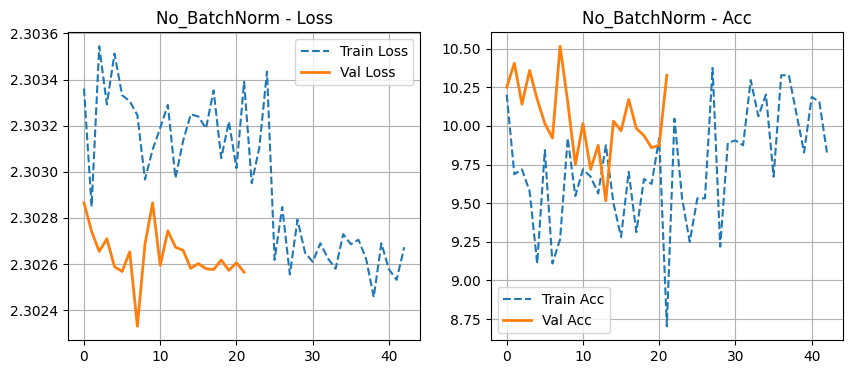


Starting: BatchNorm
>>> [BatchNorm Val] Loss: 2.30283, Acc: 9.66%
[BatchNorm] [Ep: 1, Step: 99] Train Loss: 1.90475, Acc: 27.34%
[BatchNorm] [Ep: 2, Step: 199] Train Loss: 1.61565, Acc: 37.28%
>>> [BatchNorm Val] Loss: 1.45623, Acc: 42.38%
[BatchNorm] [Ep: 3, Step: 299] Train Loss: 1.51365, Acc: 41.59%
[BatchNorm] [Ep: 4, Step: 399] Train Loss: 1.37629, Acc: 48.09%
>>> [BatchNorm Val] Loss: 1.43966, Acc: 45.19%
[BatchNorm] [Ep: 4, Step: 499] Train Loss: 1.30842, Acc: 51.27%
[BatchNorm] [Ep: 5, Step: 599] Train Loss: 1.23653, Acc: 54.78%
>>> [BatchNorm Val] Loss: 1.19477, Acc: 57.91%
[BatchNorm] [Ep: 6, Step: 699] Train Loss: 1.19210, Acc: 57.58%
[BatchNorm] [Ep: 7, Step: 799] Train Loss: 1.10069, Acc: 59.80%
>>> [BatchNorm Val] Loss: 1.14630, Acc: 58.12%
[BatchNorm] [Ep: 8, Step: 899] Train Loss: 1.07394, Acc: 61.77%
[BatchNorm] [Ep: 8, Step: 999] Train Loss: 1.06128, Acc: 63.28%
>>> [BatchNorm Val] Loss: 0.93143, Acc: 67.61%
[BatchNorm] [Ep: 9, Step: 1099] Train Loss: 0.95985, Acc: 6

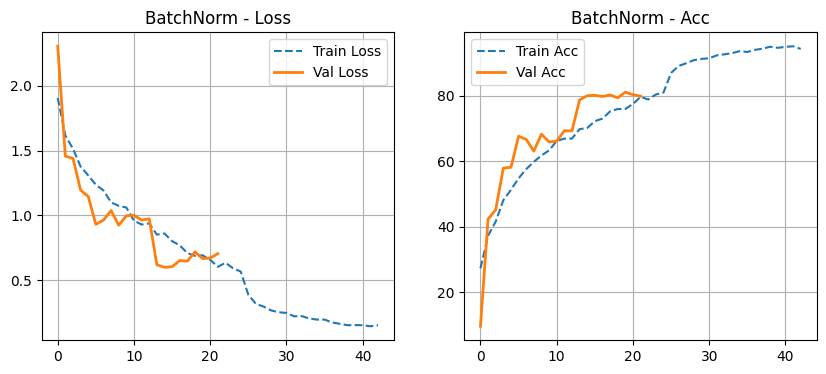


Starting: Augmentation
>>> [Augmentation Val] Loss: 2.30287, Acc: 9.98%
[Augmentation] [Ep: 1, Step: 99] Train Loss: 2.03463, Acc: 23.03%
[Augmentation] [Ep: 2, Step: 199] Train Loss: 1.73322, Acc: 32.83%
>>> [Augmentation Val] Loss: 1.58388, Acc: 41.12%
[Augmentation] [Ep: 3, Step: 299] Train Loss: 1.60474, Acc: 38.06%
[Augmentation] [Ep: 4, Step: 399] Train Loss: 1.52727, Acc: 42.30%
>>> [Augmentation Val] Loss: 1.33843, Acc: 51.17%
[Augmentation] [Ep: 4, Step: 499] Train Loss: 1.43895, Acc: 46.38%
[Augmentation] [Ep: 5, Step: 599] Train Loss: 1.33446, Acc: 50.44%
>>> [Augmentation Val] Loss: 1.10486, Acc: 59.17%
[Augmentation] [Ep: 6, Step: 699] Train Loss: 1.26604, Acc: 53.61%
[Augmentation] [Ep: 7, Step: 799] Train Loss: 1.18474, Acc: 57.06%
>>> [Augmentation Val] Loss: 1.18253, Acc: 58.34%
[Augmentation] [Ep: 8, Step: 899] Train Loss: 1.13929, Acc: 58.42%
[Augmentation] [Ep: 8, Step: 999] Train Loss: 1.09583, Acc: 60.50%
>>> [Augmentation Val] Loss: 1.05285, Acc: 62.09%
[Augment

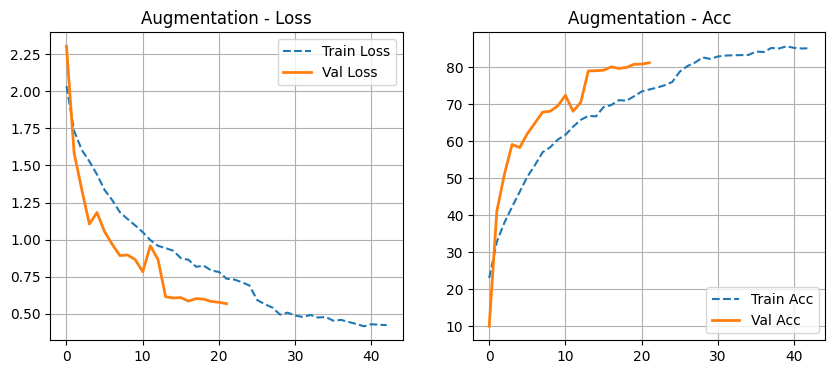


📊 REZULTATE FINALE:


,Model,Hidden1,Hidden2,BatchNorm,Augmentation,Optimizator,LR,Final Val Acc,Final Val Loss
0,No_BatchNorm,2048,512,False,False,sgd,0.0100,10.33%,2.3026
1,BatchNorm,2048,512,True,False,sgd,0.0100,79.81%,0.7056
2,Augmentation,1024,512,True,True,adam,0.0001,81.27%,0.5682



🧩 Matricea de Confuzie pentru: Augmentation (Acc: 81.27%)


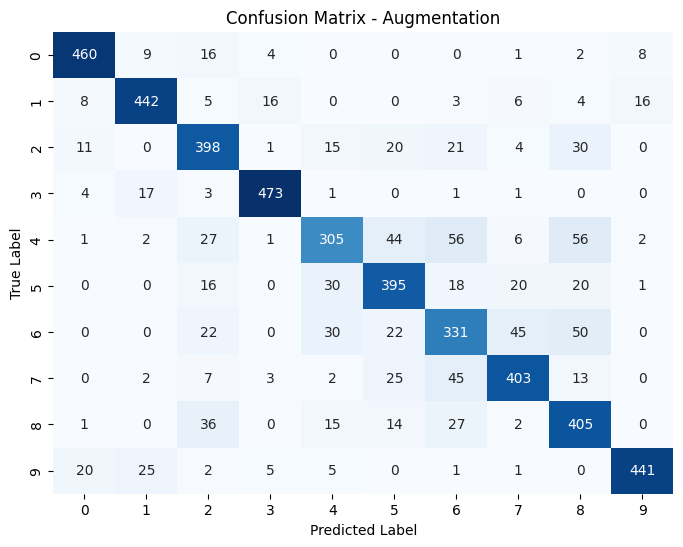


✅ Done! Best model: Augmentation with 81.27% accuracy


In [ ]:
print("\nFinal results:")
df = pd.DataFrame(results_table)
display.display(df)

print(f"\nConfusion Matrix for: {best_model_name} (Acc: {best_acc:.2f}%)")

final_net = MiniVGG(num_classes=10, in_size=best_config['input'], hidden_size1=best_config['hidden1'], hidden_size2=best_config['hidden2'],
                    use_batch_norm=best_config['batch_norm'], dropout_val=best_config['dropout_val']).to(device)

final_net.load_state_dict(best_model_state)
final_net.eval()

all_preds = []
all_labels = []

final_test_loader = torch.utils.data.DataLoader(test_images, batch_size=64, shuffle=False, num_workers=2)

with torch.no_grad():
    for inputs, labels in final_test_loader:
        inputs = inputs.to(device)
        outputs = final_net(inputs)
        _, preds = torch.max(outputs, 1)
        all_preds.extend(preds.cpu().numpy())
        all_labels.extend(labels.numpy())

cm = confusion_matrix(all_labels, all_preds)
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False)
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.title(f'Confusion Matrix - {best_model_name}')
plt.show()

print(f"\nBest model: {best_model_name} with {best_acc:.2f}% accuracy")

In [ ]:
path_to_zip_file = "/content/land_patches.zip"
directory_to_extract_to = "images"

if not os.path.exists(directory_to_extract_to):
    os.makedirs(directory_to_extract_to)

with zipfile.ZipFile(path_to_zip_file, 'r') as zip_ref:
    zip_ref.extractall(directory_to_extract_to)

## Exploratory data analysis for image classification - land_patches

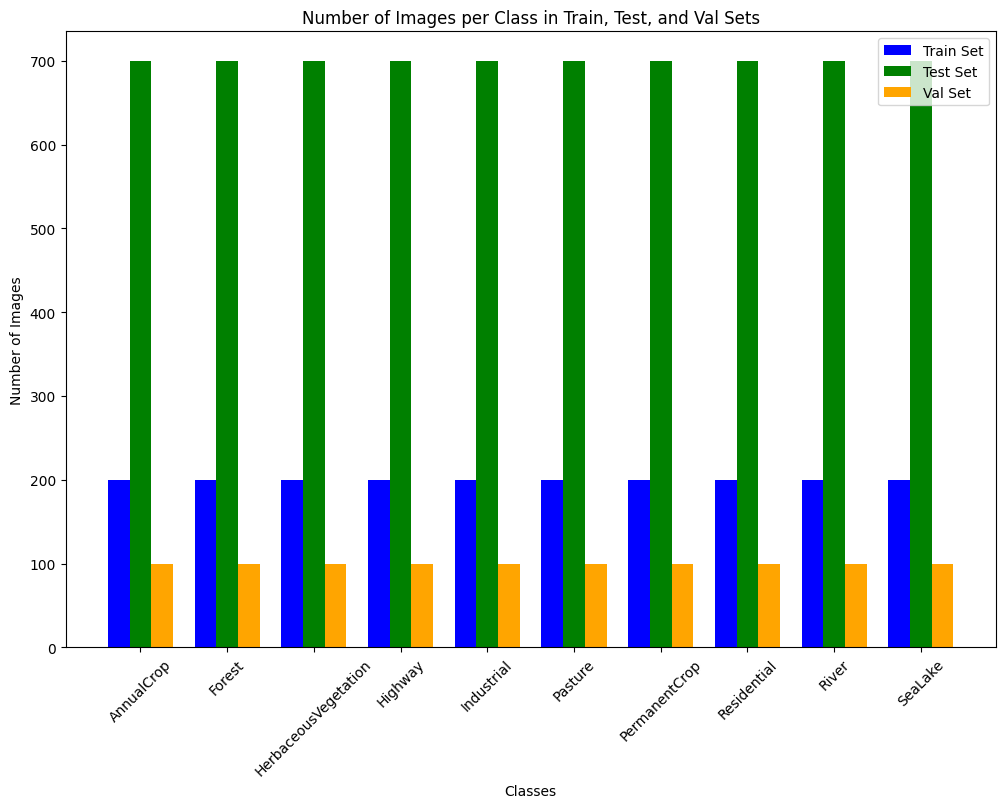

In [ ]:
land_patches_train_dir_path = 'images/land_patches/train/'
land_patches_test_dir_path = 'images/land_patches/test/'
land_patches_val_dir_path = 'images/land_patches/val/'

class_names = []
for d in os.listdir(land_patches_train_dir_path):
  if os.path.isdir(os.path.join(land_patches_train_dir_path, d)):
    class_names.append(d)
class_names.sort()

number_classes = {}
for class_name in class_names:
    train_class_dir = os.path.join(land_patches_train_dir_path, class_name)
    test_class_dir = os.path.join(land_patches_test_dir_path, class_name)
    val_class_dir = os.path.join(land_patches_val_dir_path, class_name)

    train_count = len(os.listdir(train_class_dir))
    test_count = len(os.listdir(test_class_dir))
    val_count = len(os.listdir(val_class_dir))

    number_classes[class_name] = {'train_count': train_count, 'test_count': test_count, 'val_count': val_count}

labels = list(number_classes.keys())
train_vals = []
test_vals = []
val_vals = []
for v in number_classes.values():
    train_vals.append(v['train_count'])
    test_vals.append(v['test_count'])
    val_vals.append(v['val_count'])

x = np.arange(len(labels))
width = 0.25

fig = plt.subplots(figsize=(12, 8))
plt.bar(x - width, train_vals, width, label='Train Set', color='blue')
plt.bar(x, test_vals, width, label='Test Set', color='green')
plt.bar(x + width, val_vals, width, label='Val Set', color='orange')

plt.xlabel('Classes')
plt.ylabel('Number of Images')
plt.title('Number of Images per Class in Train, Test, and Val Sets')
plt.xticks(x, labels, rotation=45)
plt.legend()
plt.show()

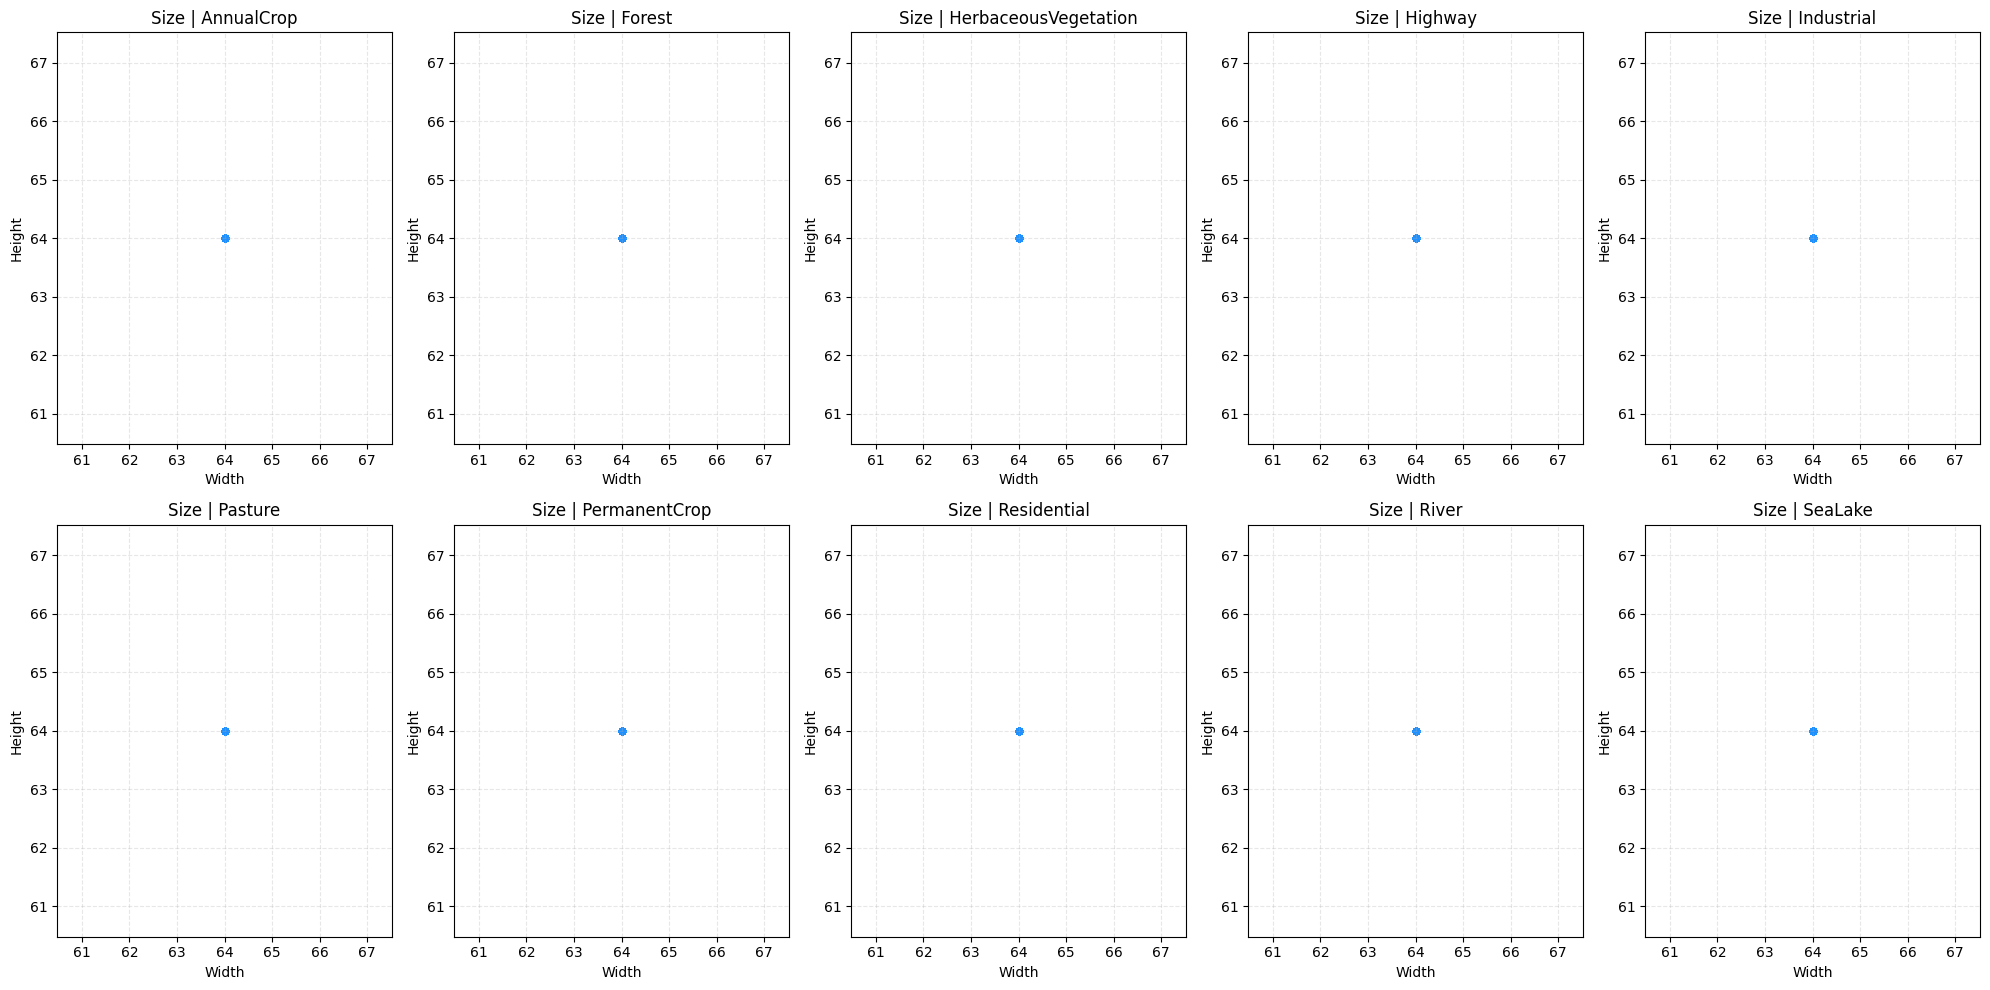

In [ ]:
class_data = {}
for class_name in class_names:
    class_dir = os.path.join(land_patches_train_dir_path, class_name)
    images = os.listdir(class_dir)

    widths = []
    heights = []

    for img_name in images:
        if img_name.lower().endswith(('.jpg')):
            img_path = os.path.join(class_dir, img_name)
            with Image.open(img_path) as img:
                w, h = img.size
                widths.append(w)
                heights.append(h)

    class_data[class_name] = {'widths': widths, 'heights': heights}


fig, ax = plt.subplots(nrows=2, ncols=5, figsize=(20, 10))
for idx, class_name in enumerate(class_names):

    width = class_data[class_name]['widths']
    height = class_data[class_name]['heights']

    row_idx = idx // 5
    col_idx = idx % 5

    ax[row_idx, col_idx].scatter(width, height, alpha=0.5, s=20, color='dodgerblue')
    ax[row_idx, col_idx].set_title(f'Size | {class_name}')
    ax[row_idx, col_idx].set_xlabel('Width')
    ax[row_idx, col_idx].set_ylabel('Height')
    ax[row_idx, col_idx].grid(True, linestyle='--', alpha=0.3)

plt.tight_layout()
plt.show()

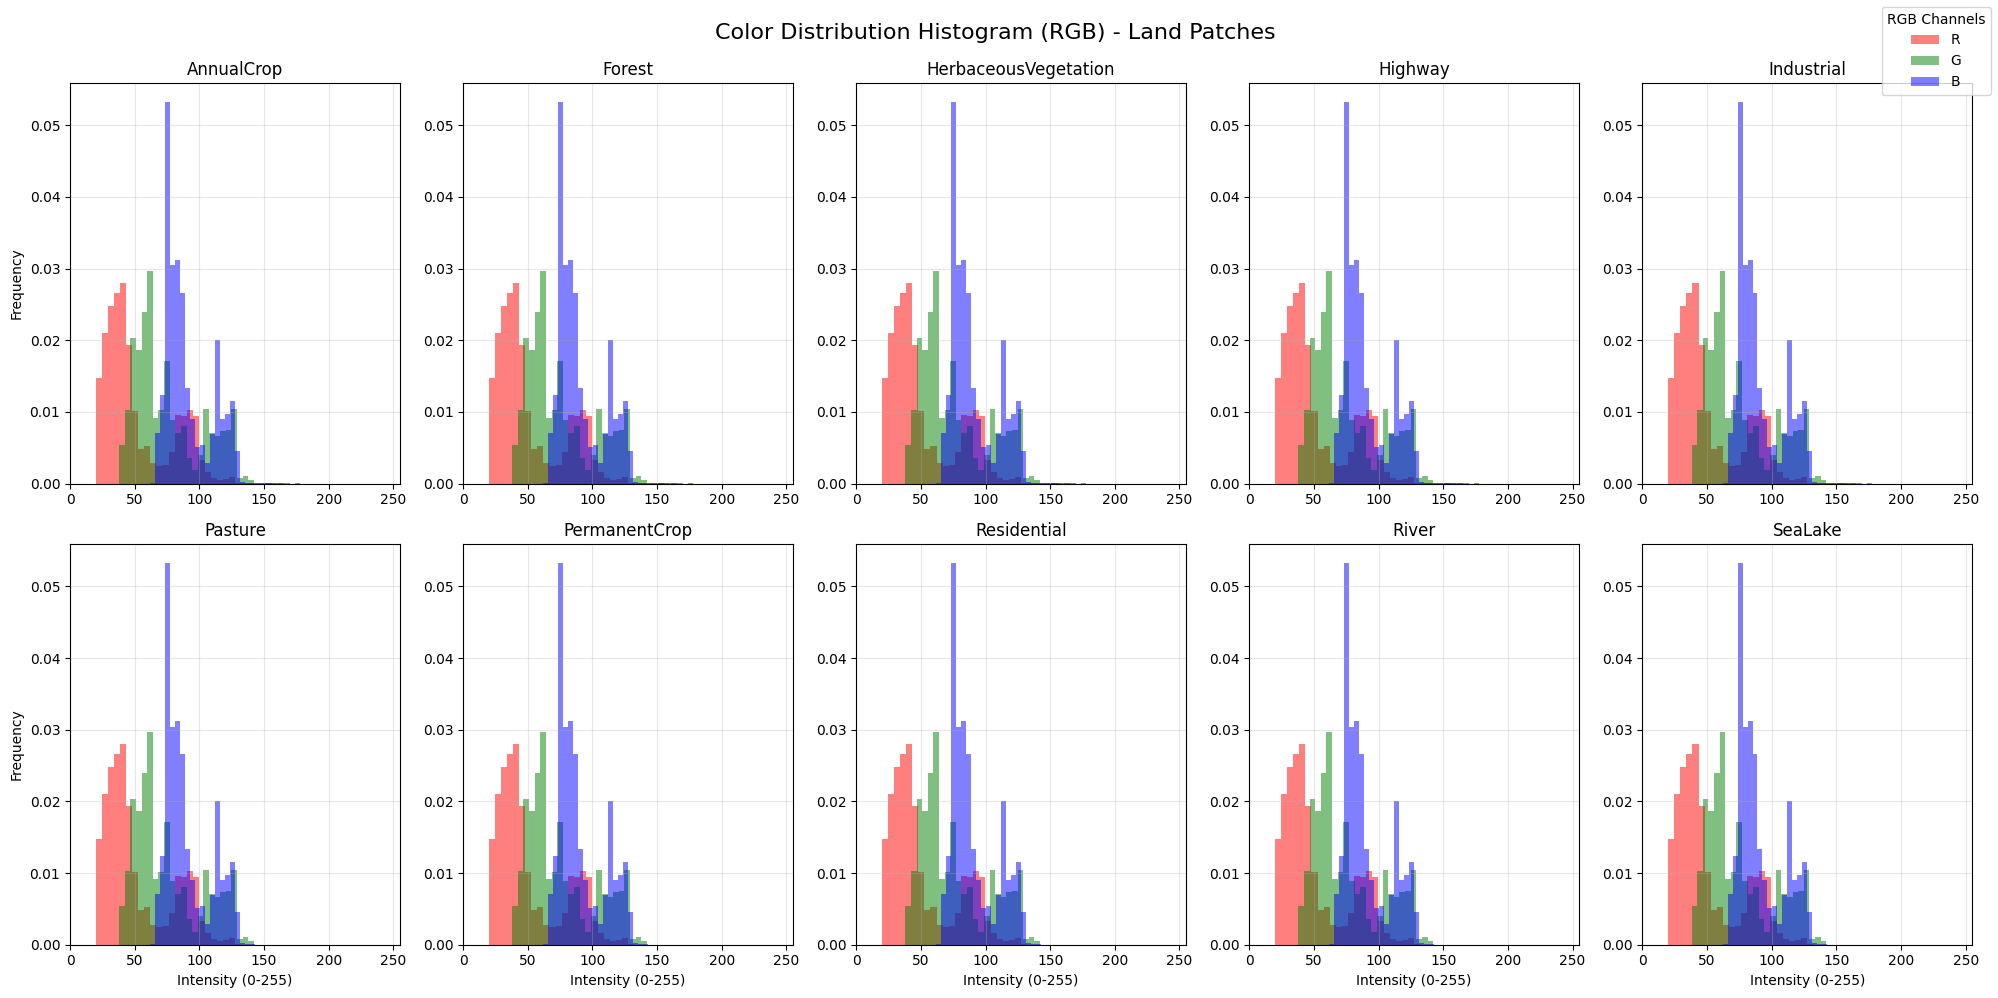

In [ ]:
rgb_class = {}

for idx, class_name in enumerate(class_names):
    class_dir = os.path.join(land_patches_train_dir_path, class_name)

    images = os.listdir(class_dir)
    if len(images) > 100:
        images = images[:100]

    all_reds = []
    all_greens = []
    all_blues = []

    for img_name in images:
        if img_name.lower().endswith(('.jpg')):
            img_path = os.path.join(class_dir, img_name)
            with Image.open(img_path).convert('RGB') as img:
                img_array = np.array(img)
                all_reds.extend(img_array[:, :, 0].flatten())
                all_greens.extend(img_array[:, :, 1].flatten())
                all_blues.extend(img_array[:, :, 2].flatten())

    rgb_class[class_name] = { 'red': all_reds, 'green': all_greens, 'blue': all_blues }

fig, ax = plt.subplots(nrows=2, ncols=5, figsize=(20, 10))
for idx, class_name in enumerate(class_names):
    red = rgb_class[class_name]["red"]
    green = rgb_class[class_name]["green"]
    blue = rgb_class[class_name]["blue"]

    row_idx = idx // 5
    col_idx = idx % 5

    ax[row_idx, col_idx].hist(all_reds, bins=50, color='red', alpha=0.5, label='R', density=True)
    ax[row_idx, col_idx].hist(all_greens, bins=50, color='green', alpha=0.5, label='G', density=True)
    ax[row_idx, col_idx].hist(all_blues, bins=50, color='blue', alpha=0.5, label='B', density=True)
    ax[row_idx, col_idx].set_title(f'{class_name}')
    ax[row_idx, col_idx].set_xlim(0, 255)

    if idx % 5 == 0:
        ax[row_idx, col_idx].set_ylabel('Frequency')
    if idx >= 5:
        ax[row_idx, col_idx].set_xlabel('Intensity (0-255)')

    ax[row_idx, col_idx].grid(True, alpha=0.3)

handles, labels = ax[row_idx, col_idx].get_legend_handles_labels()
fig.legend(handles, labels, loc='upper right', title="RGB Channels")

plt.suptitle("Color Distribution Histogram (RGB) - Land Patches", fontsize=16)
plt.tight_layout()
plt.subplots_adjust(top=0.92)
plt.show()

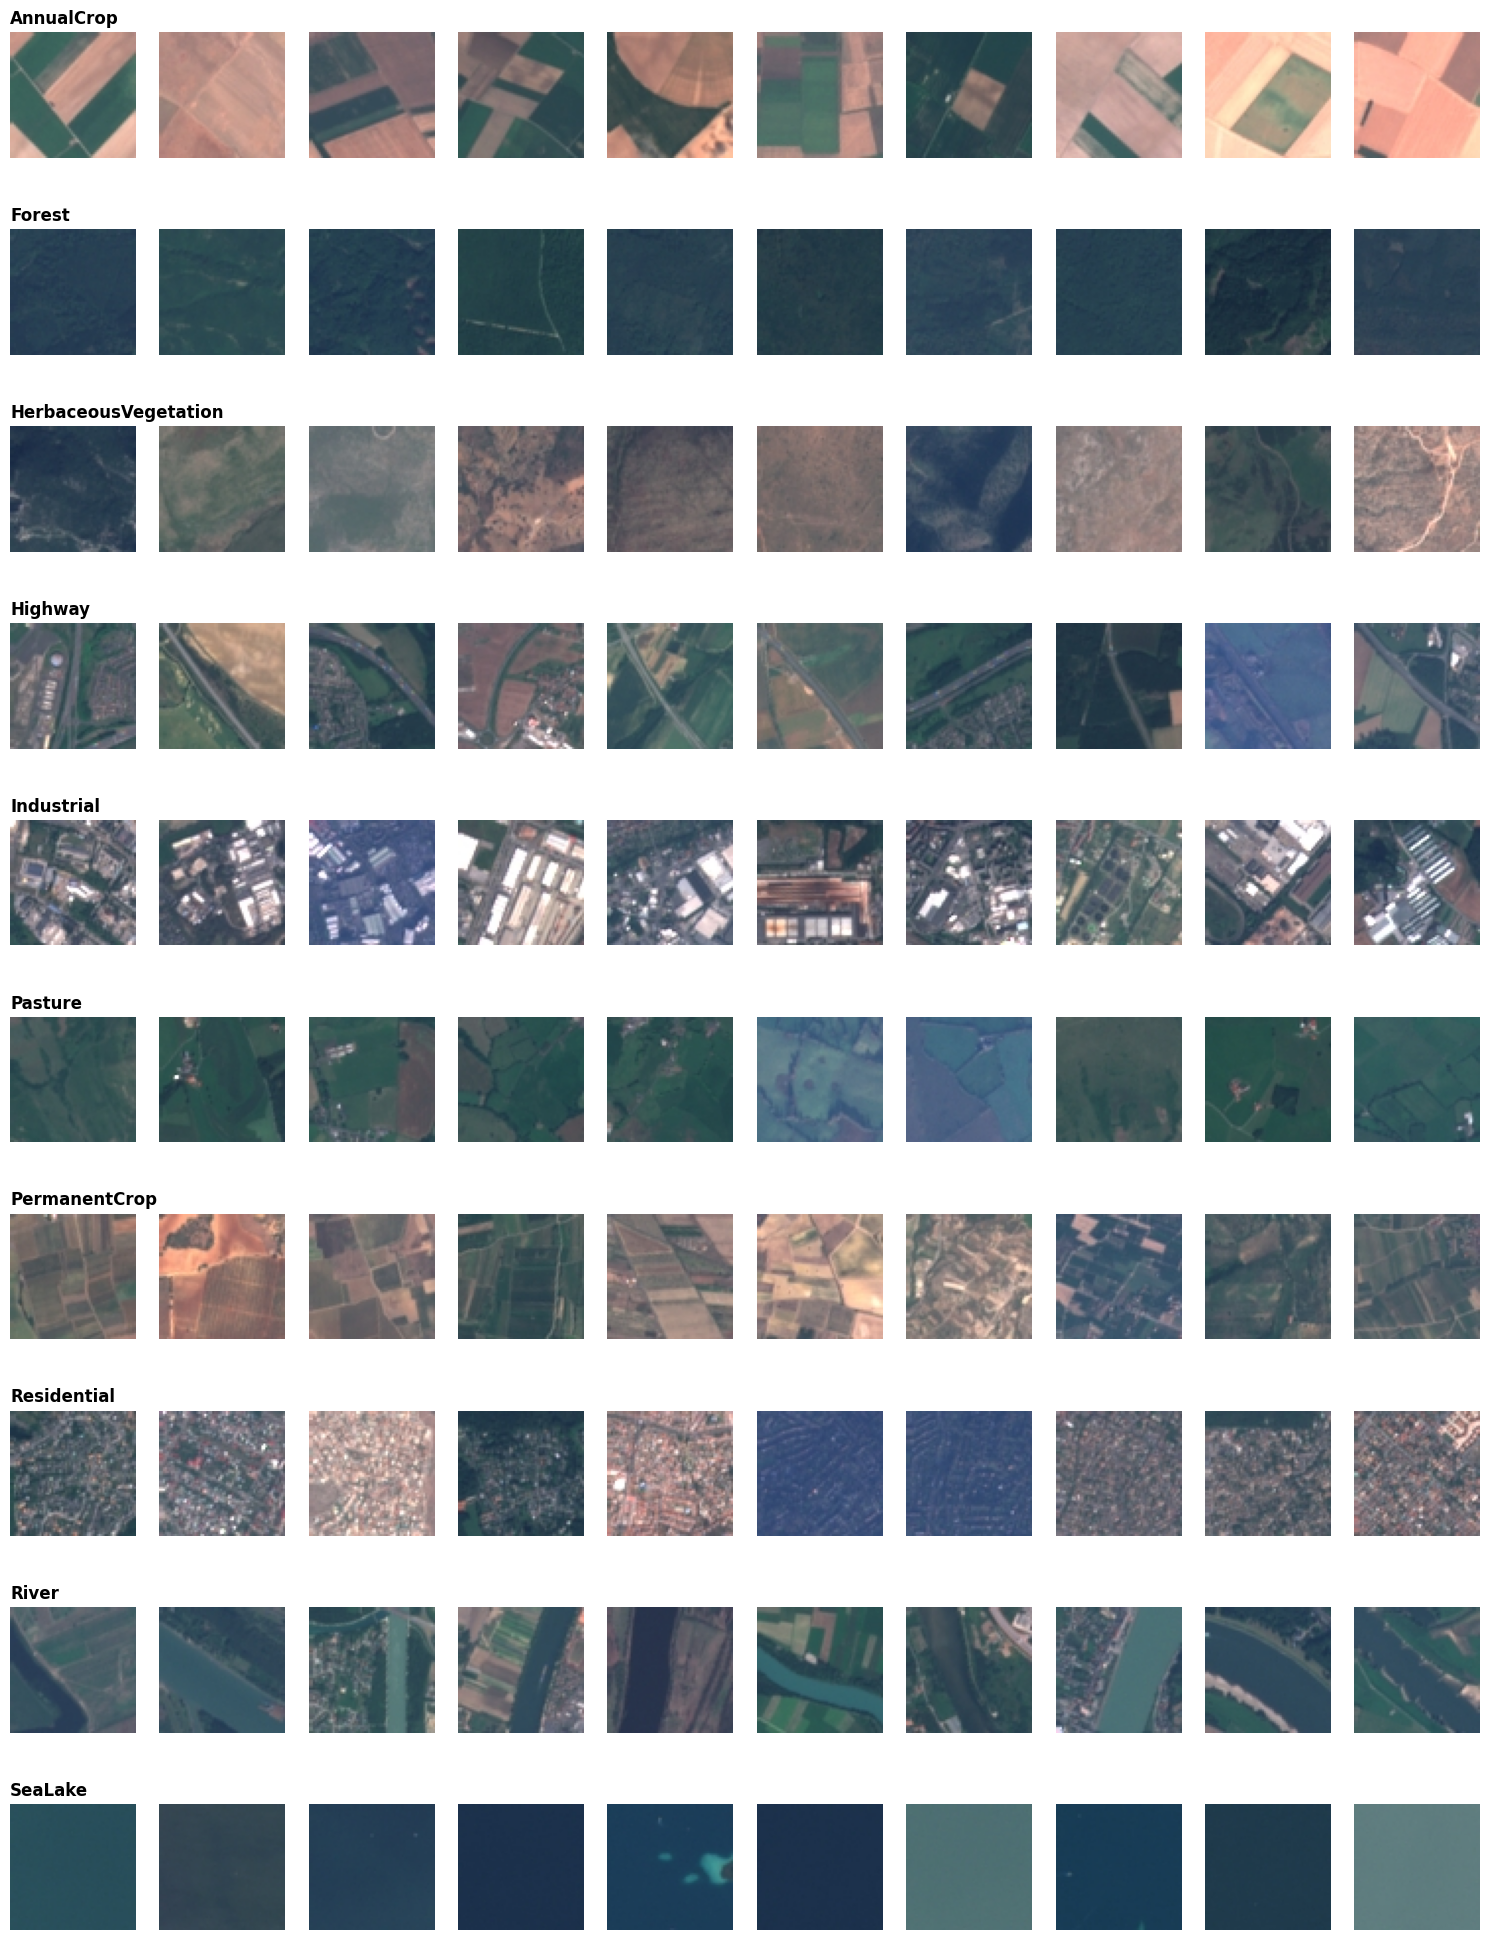

In [ ]:
fig, ax = plt.subplots(nrows=len(class_names), ncols=10, figsize=(15, 20))

for row_idx, class_name in enumerate(class_names):
    class_dir = os.path.join(land_patches_train_dir_path, class_name)
    all_imgs = []
    for f in os.listdir(class_dir):
        if f.lower().endswith(('.jpg')):
            all_imgs.append(f)

    current_samples = random.sample(all_imgs, min(len(all_imgs), 10))
    for col_idx, img_name in enumerate(current_samples):
        img_path = os.path.join(class_dir, img_name)
        with Image.open(img_path) as img:
            ax[row_idx, col_idx].imshow(img)
            ax[row_idx, col_idx].axis('off')
            if col_idx == 0:
                ax[row_idx, col_idx].set_title(f'{class_name}', fontsize=12, fontweight='bold', loc='left')

plt.tight_layout()
plt.show()

In [ ]:
if torch.cuda.is_available():
  device = torch.device("cuda")
else:
  device = torch.device("cpu")

print(f"Running on device: {device}")

train_transform_land = transforms.Compose([
    transforms.Resize((64, 64)),
    transforms.ToTensor(),
    transforms.Normalize([0.5, 0.5, 0.5], [0.5, 0.5, 0.5])
])

train_transform_land_aug = transforms.Compose([
    transforms.Resize((64, 64)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(degrees=15),
    transforms.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2),
    transforms.RandomAffine(degrees=0, translate=(0.1, 0.1)),
    transforms.ToTensor(),
    transforms.Normalize([0.5, 0.5, 0.5], [0.5, 0.5, 0.5])
])

val_transform_land = transforms.Compose([
    transforms.Resize((64, 64)),
    transforms.ToTensor(),
    transforms.Normalize([0.5, 0.5, 0.5], [0.5, 0.5, 0.5])
])

test_transform_land = transforms.Compose([
    transforms.Resize((64, 64)),
    transforms.ToTensor(),
    transforms.Normalize([0.5, 0.5, 0.5], [0.5, 0.5, 0.5])
])

train_images_land_aug = torchvision.datasets.ImageFolder(root=land_patches_train_dir_path, transform=train_transform_land_aug)
train_images_land = torchvision.datasets.ImageFolder(root=land_patches_train_dir_path, transform=train_transform_land)
val_images_land = torchvision.datasets.ImageFolder(root=land_patches_val_dir_path, transform=val_transform_land)
test_images_land = torchvision.datasets.ImageFolder(root=land_patches_test_dir_path, transform=test_transform_land)

print(f'Size of training labels {len(train_images_land.targets)}')
print(f'Size of augmented training labels {len(train_images_land_aug)}')
print(f'Size of test labels {len(test_images_land.targets)}')
print(f'Size of validation labels {len(val_images_land.targets)}')

Running on device: cuda
Size of training labels 2000
Size of augmented training labels 2000
Size of test labels 7000
Size of validation labels 1000


In [ ]:
BATCH_SIZE_TRAIN = 64
BATCH_SIZE_TEST = 64
BATCH_SIZE_VALIDATION = 64
NO_WORKERS = 8
SHUFFLE_DATA = True

train_land_loader = torch.utils.data.DataLoader(train_images_land, batch_size=BATCH_SIZE_TRAIN, shuffle=SHUFFLE_DATA, num_workers=NO_WORKERS)
(batch_train_land_images, batch_train_land_labels) = next(iter(train_land_loader))

print(f'Shape of training images: {batch_train_land_images.size()}')
print(f'Shape of training labels: {batch_train_land_labels.size()}')

train_land_loader_aug = torch.utils.data.DataLoader(train_images_land_aug, batch_size=BATCH_SIZE_TRAIN, shuffle=SHUFFLE_DATA, num_workers=NO_WORKERS)
(batch_train_land_images_aug, batch_train_land_labels_aug) = next(iter(train_land_loader_aug))
print(f'Shape of augmented training images: {batch_train_land_images_aug.size()}')
print(f'Shape of augmented training labels: {batch_train_land_labels_aug.size()}')

val_land_loader = torch.utils.data.DataLoader(val_images_land, batch_size=BATCH_SIZE_VALIDATION, shuffle=SHUFFLE_DATA, num_workers=NO_WORKERS)
(batch_val_land_images, batch_val_land_labels) = next(iter(val_land_loader))
print(f'Shape of validation images: {batch_val_land_images.size()}')
print(f'Shape of validation labels: {batch_val_land_labels.size()}')

Shape of training images: torch.Size([64, 3, 64, 64])
Shape of training labels: torch.Size([64])
Shape of augmented training images: torch.Size([64, 3, 64, 64])
Shape of augmented training labels: torch.Size([64])
Shape of validation images: torch.Size([64, 3, 64, 64])
Shape of validation labels: torch.Size([64])


In [ ]:
test_land_loader = torch.utils.data.DataLoader(test_images_land, batch_size=BATCH_SIZE_TEST, shuffle=SHUFFLE_DATA, num_workers=NO_WORKERS)

def loopy_test_loader(dl):
    data_iter = iter(dl)

    while True:
        try:
            yield next(data_iter)
        except StopIteration:
            data_iter = iter(dl)
            yield next(data_iter)

(batch_test_land_images, batch_test_land_labels) = next(iter(test_land_loader))
print(f'Shape of test images: {batch_test_land_images.size()}')
print(f'Shape of test labels: {batch_test_land_labels.size()}')

Shape of test images: torch.Size([64, 3, 64, 64])
Shape of test labels: torch.Size([64])


In [ ]:
def plot_losses(loss_list, steps, ct):
    if ct % 1000 == 0:
        display.clear_output(wait=True)

    display.display(plt.gcf())
    plt.plot(steps, loss_list, c='b')
    time.sleep(1.0)

def get_num_params(model):
    num_params = 0
    for params in model.parameters():
        num_params += params.shape.numel()

    return num_params

def top_k_accuracy(k, target, output):
    batch_size = target.size(0)

    _, pred = output.topk(k, 1, True, True)

    pred = pred.t()
    correct = pred.eq(target.to(device).view(1, -1).expand_as(pred))

    correct_k = correct[:k].view(-1).float().sum(0, keepdim=True)
    correct_k.mul_(100.0 / batch_size)

    return correct_k

In [ ]:
def train_engine_land(net, train_data_loader, val_data_loader, optimizer, scheduler, num_epochs=35, name="Experiment"):

    history = {
        'train_loss': [], 'train_acc': [], 'train_steps': [],
        'val_loss': [], 'val_acc': [], 'val_steps': []
    }

    train_iter = 0
    running_loss = 0.0
    running_acc = 0.0

    val_data_provider = loopy_test_loader(val_data_loader)

    net.train()

    for epoch in range(num_epochs):
        for i, data in enumerate(train_data_loader, 0):

            inputs, labels = data[0].to(device), data[1].to(device)
            optimizer.zero_grad()
            outputs = net(inputs)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()

            running_loss += loss.item()
            running_acc += top_k_accuracy(1, labels, outputs).item()

            if train_iter % REPORT_TRAIN_EVERY == REPORT_TRAIN_EVERY - 1:
                train_loss = running_loss / REPORT_TRAIN_EVERY
                train_acc = running_acc / REPORT_TRAIN_EVERY

                print(f'[{name}] [Ep: {epoch+1}, Step: {train_iter}] Train Loss: {train_loss:.5f}, Acc: {train_acc:.2f}%')

                history['train_loss'].append(train_loss)
                history['train_acc'].append(train_acc)
                history['train_steps'].append(train_iter)

                running_loss = 0.0
                running_acc = 0.0

            if train_iter % REPORT_TEST_EVERY == 0:
                net.eval()
                with torch.no_grad():
                    val_iter = 0
                    val_loss_accum = 0.0
                    val_acc_accum = 0.0

                    while val_iter < TEST_ITERS:
                        try:
                            val_data = next(val_data_provider)
                        except StopIteration:
                            val_data_provider = loopy_test_loader(val_data_loader)
                            val_data = next(val_data_provider)

                        v_in, v_lbl = val_data[0].to(device), val_data[1].to(device)
                        v_out = net(v_in)

                        val_loss_accum += criterion(v_out, v_lbl).item()
                        val_acc_accum += top_k_accuracy(1, v_lbl, v_out).item()
                        val_iter += 1

                    avg_val_loss = val_loss_accum / TEST_ITERS
                    avg_val_acc = val_acc_accum / TEST_ITERS

                    if name == "Validation":
                        print(f'>>> [{name} VALIDATION] Loss: {avg_val_loss:.5f}, Acc: {avg_val_acc:.2f}%')
                    else:
                      print(f'>>> [{name} Test] Loss: {avg_val_loss:.5f}, Acc: {avg_val_acc:.2f}%')


                    history['val_loss'].append(avg_val_loss)
                    history['val_acc'].append(avg_val_acc)
                    history['val_steps'].append(train_iter)

                net.train()

            train_iter += 1

        scheduler.step()

    print(f"Finished: {name}")
    return history

In [ ]:
import torch.nn as nn

class MLP(nn.Module):
    def __init__(self, img_size = 64, hidden_size=512, out_size=256, num_classes=10, dropout_val=0.5):
        super(MLP, self).__init__()

        self.in_size = 3 * img_size * img_size

        self.fc1 = nn.Linear(self.in_size, hidden_size)
        self.fc2 = nn.Linear(hidden_size, out_size)
        self.fc3 = nn.Linear(out_size, num_classes)

        self.relu = nn.ReLU(inplace=True)
        self.dropout = nn.Dropout(p=dropout_val)

    def forward(self, x):
        x = x.view(x.size(0), -1)

        x = self.relu(self.fc1(x))
        x = self.dropout(x)

        x = self.relu(self.fc2(x))
        x = self.dropout(x)

        x = self.fc3(x)

        return x

In [ ]:
import torch
import torch.nn as nn

class LeNet(nn.Module):
    def __init__(self, img_size=64, num_classes=10, in_size=512, hidden_size1=1024, hidden_size2=1024, use_batch_norm=False, dropout_val=0.5):
        super(LeNet, self).__init__()

        self.conv1 = nn.Conv2d(in_channels=3, out_channels=6, kernel_size=5)
        if use_batch_norm:
            self.bn1 = nn.BatchNorm2d(6)
        else:
            self.bn1 = nn.Identity()

        self.conv2 = nn.Conv2d(in_channels=6, out_channels=16, kernel_size=5)
        if use_batch_norm:
            self.bn2 = nn.BatchNorm2d(16)
        else:
            self.bn2 = nn.Identity()

        self.pool = nn.MaxPool2d(kernel_size=2, stride=2)

        self.size = img_size - 5 + 1
        self.size = self.size // 2
        self.size = self.size - 5 + 1
        self.size = self.size // 2

        flatten_size = 16 * self.size * self.size

        self.fc1 = nn.Linear(in_features=flatten_size, out_features=hidden_size1)
        self.fc2 = nn.Linear(in_features=hidden_size1, out_features=hidden_size2)
        self.fc3 = nn.Linear(in_features=hidden_size2, out_features=num_classes)

        self.relu = nn.ReLU(inplace=True)
        self.dropout = nn.Dropout(p=dropout_val)

    def forward(self, x):
        x = self.relu(self.bn1(self.conv1(x)))
        x = self.pool(x)

        x = self.relu(self.bn2(self.conv2(x)))
        x = self.pool(x)

        x = x.view(x.size(0), -1)

        x = self.relu(self.fc1(x))
        x = self.dropout(x)

        x = self.relu(self.fc2(x))
        x = self.dropout(x)

        x = self.fc3(x)

        return x

In [ ]:
experiments = [
    {
        "name": "MLP_Safe_SGD",
        "hidden_size": 512,
        "dropout_val": 0.5,
        "lr": 0.01,
        "optimizer": "sgd",
        "augmentation": False
    },
    {
        "name": "MLP_Small_Adam",
        "hidden_size": 256,
        "dropout_val": 0.4,
        "lr": 0.001,
        "optimizer": "adam",
        "augmentation": False
    },
    {
        "name": "MLP_Large_HighReg",
        "hidden_size": 1024,
        "dropout_val": 0.5,
        "lr": 0.001,
        "optimizer": "adam",
        "augmentation": False
    },
    {
        "name": "MLP_Power_Adam",
        "hidden_size": 1024,
        "dropout_val": 0.3,
        "lr": 0.001,
        "optimizer": "adam",
        "augmentation": True
    },
    {
        "name": "MLP_Wide_SGD",
        "hidden_size": 1024,
        "dropout_val": 0.4,
        "lr": 0.01,
        "optimizer": "sgd",
        "augmentation": True
    },
    {
        "name": "MLP_Balanced_Adam",
        "hidden_size": 512,
        "dropout_val": 0.3,
        "lr": 0.001,
        "optimizer": "adam",
        "augmentation": True
    }
]

best_acc = 0.0
best_model_name = None
best_config = {}
all_results = []

for exp in experiments:
    print(f"\n{'='*60}")
    print(f"Starting: {exp['name']}")
    print(f"{'='*60}")

    net = MLP(img_size=64, hidden_size=exp['hidden_size'], dropout_val=exp['dropout_val']).to(device)

    if exp['augmentation']:
        current_train_loader = train_loader_aug
        num_epochs = 40
    else:
        current_train_loader = train_loader
        num_epochs = 20

    if exp['optimizer'] == 'sgd':
        optimizer = optim.SGD(net.parameters(), lr=exp['lr'], momentum=0.9, weight_decay=1e-4)
    else:
        optimizer = optim.Adam(net.parameters(), lr=exp['lr'], weight_decay=1e-4)

    scheduler = torch.optim.lr_scheduler.MultiStepLR(optimizer, milestones=[15, 25], gamma=0.1)

    hist = train_engine_land(net=net, train_data_loader=current_train_loader, val_data_loader=val_land_loader,
                             optimizer=optimizer, scheduler=scheduler, num_epochs=num_epochs, name=exp['name'])

    plt.figure(figsize=(10, 4))

    plt.subplot(1, 2, 1)
    plt.plot(hist['train_loss'], label='Train Loss', linestyle='--')
    plt.plot(hist['val_loss'], label='Test Loss', linewidth=2)
    plt.title(f"{exp['name']} - Loss")
    plt.legend()
    plt.grid()

    plt.subplot(1, 2, 2)
    plt.plot(hist['train_acc'], label='Train Acc', linestyle='--')
    plt.plot(hist['val_acc'], label='Test Acc', linewidth=2)
    plt.title(f"{exp['name']} - Acc")
    plt.legend()
    plt.grid()

    plt.show()

    final_acc = hist['val_acc'][-1]
    final_loss = hist['val_loss'][-1]

    if torch.is_tensor(final_acc):
        final_acc = final_acc.item()
    if torch.is_tensor(final_loss):
        final_loss = final_loss.item()

    all_results.append({
        "Model": exp['name'],
        "Hidden Size": exp['hidden_size'],
        "Dropout": exp['dropout_val'],
        "Augmentation": exp['augmentation'],
        "Optimizator": exp['optimizer'],
        "LR": exp['lr'],
        "Final Val Acc": final_acc,
        "Final Val Loss": final_loss
    })

    if final_acc > best_acc:
        best_acc = final_acc
        best_model_name = exp['name']
        best_config = exp.copy()

if all_results:
    df_results = pd.DataFrame(all_results)

    df_display = df_results.copy()
    df_display['Final Val Acc'] = df_display['Final Val Acc'].apply(lambda x: f"{x:.2f}%")
    df_display['Final Val Loss'] = df_display['Final Val Loss'].apply(lambda x: f"{x:.4f}")

    print("\nTop Results by Accuracy:")
    print(df_display.sort_values(by='Final Val Acc', ascending=False).head(6))

=== Începe Grid Search pe 36 combinații folosind VALIDATION SET ===

[1/36] Rulare MLP_Exp_1 cu params: {'hidden_size': 256, 'dropout_val': 0.3, 'lr': 0.01, 'optimizer': 'sgd'}
>>> [MLP_Exp_1 VALIDATION] Loss: 2.29185, Acc: 9.97%
>>> [MLP_Exp_1 VALIDATION] Loss: 1.62232, Acc: 39.98%
>>> [MLP_Exp_1 VALIDATION] Loss: 1.43583, Acc: 51.98%
>>> [MLP_Exp_1 VALIDATION] Loss: 1.36425, Acc: 53.25%
>>> [MLP_Exp_1 VALIDATION] Loss: 1.32601, Acc: 55.12%
>>> [MLP_Exp_1 VALIDATION] Loss: 1.31678, Acc: 56.73%
Finished: MLP_Exp_1
--> NEW RECORD (Validation)! Acc: 56.73% cu {'hidden_size': 256, 'dropout_val': 0.3, 'lr': 0.01, 'optimizer': 'sgd'}

[2/36] Rulare MLP_Exp_2 cu params: {'hidden_size': 256, 'dropout_val': 0.3, 'lr': 0.01, 'optimizer': 'adam'}
>>> [MLP_Exp_2 VALIDATION] Loss: 30.95444, Acc: 11.72%
>>> [MLP_Exp_2 VALIDATION] Loss: 1.98906, Acc: 23.84%
>>> [MLP_Exp_2 VALIDATION] Loss: 1.93022, Acc: 22.98%
>>> [MLP_Exp_2 VALIDATION] Loss: 1.79278, Acc: 29.74%
>>> [MLP_Exp_2 VALIDATION] Loss: 1.7

In [ ]:
p = best_config

if p['augmentation']:
    final_train_loader = train_loader_aug
    final_epochs = 50
else:
    final_train_loader = train_loader
    final_epochs = 30

net = MLP(img_size=64, hidden_size=p['hidden_size'], dropout_val=p['dropout_val']).to(device)

if p['optimizer'] == 'sgd':
    optimizer = optim.SGD(net.parameters(), lr=p['lr'], momentum=0.9, weight_decay=1e-4)
else:
    optimizer = optim.Adam(net.parameters(), lr=p['lr'], weight_decay=1e-4)

scheduler = torch.optim.lr_scheduler.MultiStepLR(optimizer, milestones=[20, 35], gamma=0.1)

hist = train_engine_land(net=net, train_data_loader=final_train_loader, val_data_loader=val_land_loader,
                         optimizer=optimizer, scheduler=scheduler, num_epochs=final_epochs, name="Test")

all_preds = []
all_labels = []

net.eval()
with torch.no_grad():
    for images, labels in val_land_loader:
        images = images.to(device)
        outputs = net(images)
        _, predicted = torch.max(outputs, 1)

        all_preds.extend(predicted.cpu().numpy())
        all_labels.extend(labels.numpy())

cm = confusion_matrix(all_labels, all_preds)

plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False)
plt.title("Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("True")
plt.show()

>>> [MLP_Exp_36 VALIDATION] Loss: 2.29687, Acc: 11.84%
>>> [MLP_Exp_36 VALIDATION] Loss: 1.66364, Acc: 37.14%
>>> [MLP_Exp_36 VALIDATION] Loss: 1.53282, Acc: 45.65%
>>> [MLP_Exp_36 VALIDATION] Loss: 1.38249, Acc: 54.02%
>>> [MLP_Exp_36 VALIDATION] Loss: 1.34342, Acc: 55.09%
>>> [MLP_Exp_36 VALIDATION] Loss: 1.34112, Acc: 55.11%
>>> [MLP_Exp_36 VALIDATION] Loss: 1.36907, Acc: 54.69%
>>> [MLP_Exp_36 VALIDATION] Loss: 1.32911, Acc: 55.14%
Finished: MLP_Exp_36


In [ ]:
import torch
import torch.optim as optim
import pandas as pd
import matplotlib.pyplot as plt
import copy

experiments_lenet = [
    {
        "name": "LeNet_Base_Adam_NoAug",
        "hidden_size1": 120,
        "hidden_size2": 84,
        "dropout_val": 0.5,
        "use_batch_norm": True,
        "lr": 0.001,
        "optimizer": "adam",
        "augmentation": False
    },
    {
        "name": "LeNet_SGD_Classic_NoAug",
        "hidden_size1": 120,
        "hidden_size2": 84,
        "dropout_val": 0.4,
        "use_batch_norm": True,
        "lr": 0.01,
        "optimizer": "sgd",
        "augmentation": False
    },
    {
        "name": "LeNet_Small_Reg_NoAug",
        "hidden_size1": 64,
        "hidden_size2": 32,
        "dropout_val": 0.3,
        "use_batch_norm": False,
        "lr": 0.001,
        "optimizer": "adam",
        "augmentation": False
    },
    {
        "name": "LeNet_Big_Adam_Aug",
        "hidden_size1": 256,
        "hidden_size2": 128,
        "dropout_val": 0.3,
        "use_batch_norm": True,
        "lr": 0.001,
        "optimizer": "adam",
        "augmentation": True
    },
    {
        "name": "LeNet_Wide_SGD_Aug",
        "hidden_size1": 512,
        "hidden_size2": 256,
        "dropout_val": 0.4,
        "use_batch_norm": True,
        "lr": 0.01,
        "optimizer": "sgd",
        "augmentation": True
    },
    {
        "name": "LeNet_Balanced_Aug",
        "hidden_size1": 120,
        "hidden_size2": 84,
        "dropout_val": 0.2,
        "use_batch_norm": True,
        "lr": 0.0005,
        "optimizer": "adam",
        "augmentation": True
    }
]

best_acc_lenet = 0.0
best_model_name_lenet = None
best_config_lenet = {}
all_results_lenet = []

for exp in experiments_lenet:
    print(f"\n{'='*60}")
    print(f"Starting: {exp['name']}")
    print(f"{'='*60}")

    net = LeNet(img_size=64, num_classes=10, hidden_size1=exp['hidden_size1'], hidden_size2=exp['hidden_size2'],
                use_batch_norm=exp['use_batch_norm'], dropout_val=exp['dropout_val']).to(device)

    if exp['augmentation']:
        current_train_loader = train_loader_aug
        num_epochs = 40
    else:
        current_train_loader = train_loader
        num_epochs = 20

    if exp['optimizer'] == 'sgd':
        optimizer = optim.SGD(net.parameters(), lr=exp['lr'], momentum=0.9, weight_decay=1e-4)
    else:
        optimizer = optim.Adam(net.parameters(), lr=exp['lr'], weight_decay=1e-4)

    scheduler = torch.optim.lr_scheduler.MultiStepLR(optimizer, milestones=[15, 25], gamma=0.1)

    hist = train_engine_land(net=net, train_data_loader=current_train_loader, val_data_loader=val_land_loader,
                             optimizer=optimizer, scheduler=scheduler, num_epochs=num_epochs, name="Validation")

    plt.figure(figsize=(10, 4))

    plt.subplot(1, 2, 1)
    plt.plot(hist['train_loss'], label='Train Loss', linestyle='--')
    plt.plot(hist['val_loss'], label='Val Loss', linewidth=2)
    plt.title(f"{exp['name']} - Loss")
    plt.legend()
    plt.grid()

    plt.subplot(1, 2, 2)
    plt.plot(hist['train_acc'], label='Train Acc', linestyle='--')
    plt.plot(hist['val_acc'], label='Val Acc', linewidth=2)
    plt.title(f"{exp['name']} - Acc")
    plt.legend()
    plt.grid()

    plt.show()

    final_acc = hist['val_acc'][-1]
    final_loss = hist['val_loss'][-1]

    if torch.is_tensor(final_acc): final_acc = final_acc.item()
    if torch.is_tensor(final_loss): final_loss = final_loss.item()

    all_results_lenet.append({
        "Model": exp['name'],
        "H1": exp['hidden_size1'],
        "H2": exp['hidden_size2'],
        "BN": exp['use_batch_norm'],
        "Aug": exp['augmentation'],
        "Opt": exp['optimizer'],
        "Final Acc": final_acc,
        "Final Loss": final_loss
    })

    if final_acc > best_acc_lenet:
        best_acc_lenet = final_acc
        best_config_lenet = exp.copy()
        best_model_name_lenet = exp['name']

if all_results_lenet:
    df_lenet = pd.DataFrame(all_results_lenet)

    df_display = df_lenet.copy()
    df_display['Final Acc'] = df_display['Final Acc'].apply(lambda x: f"{x:.2f}%")
    df_display['Final Loss'] = df_display['Final Loss'].apply(lambda x: f"{x:.4f}")

    print("\nTop Results LeNet by Accuracy:")
    print(df_display.sort_values(by='Final Acc', ascending=False).head(6))

=== Începe Grid Search LeNet pe 32 combinații ===
Device folosit: cuda

[1/32] Rulare LeNet_Exp_1 cu params: {'hidden_size1': 120, 'hidden_size2': 84, 'dropout_val': 0.3, 'use_batch_norm': True, 'lr': 0.001, 'optimizer': 'adam'}
>>> [LeNet_Exp_1 VALIDATION] Loss: 2.30002, Acc: 17.38%
>>> [LeNet_Exp_1 VALIDATION] Loss: 1.45525, Acc: 48.21%
>>> [LeNet_Exp_1 VALIDATION] Loss: 0.84716, Acc: 71.62%
>>> [LeNet_Exp_1 VALIDATION] Loss: 0.73940, Acc: 74.09%
>>> [LeNet_Exp_1 VALIDATION] Loss: 0.73339, Acc: 74.41%
Finished: LeNet_Exp_1
--> NEW RECORD (Validation)! Acc: 74.41% cu {'hidden_size1': 120, 'hidden_size2': 84, 'dropout_val': 0.3, 'use_batch_norm': True, 'lr': 0.001, 'optimizer': 'adam'}

[2/32] Rulare LeNet_Exp_2 cu params: {'hidden_size1': 120, 'hidden_size2': 84, 'dropout_val': 0.3, 'use_batch_norm': True, 'lr': 0.001, 'optimizer': 'sgd'}
>>> [LeNet_Exp_2 VALIDATION] Loss: 2.30503, Acc: 9.56%
>>> [LeNet_Exp_2 VALIDATION] Loss: 1.54676, Acc: 46.27%
>>> [LeNet_Exp_2 VALIDATION] Loss: 1.

In [ ]:
import torch.optim as optim

p = best_config_lenet

if p['augmentation']:
    final_train_loader = train_loader_aug
    final_epochs = 40
else:
    final_train_loader = train_loader
    final_epochs = 20

net = LeNet(img_size=64, num_classes=10, hidden_size1=p['hidden_size1'], hidden_size2=p['hidden_size2'],
            use_batch_norm=p['use_batch_norm'], dropout_val=p['dropout_val']).to(device)

if p['optimizer'] == 'sgd':
    optimizer = optim.SGD(net.parameters(), lr=p['lr'], momentum=0.9, weight_decay=1e-4)
else:
    optimizer = optim.Adam(net.parameters(), lr=p['lr'], weight_decay=1e-4)

scheduler = torch.optim.lr_scheduler.MultiStepLR(optimizer, milestones=[15, 25], gamma=0.1)

hist = train_engine_land(net=net, train_data_loader=final_train_loader, val_data_loader=test_land_loader,
                         optimizer=optimizer, scheduler=scheduler, num_epochs=final_epochs, name="Test")

all_preds = []
all_labels = []

net.eval()
with torch.no_grad():
    for images, labels in test_land_loader:
        images = images.to(device)
        outputs = net(images)
        _, predicted = torch.max(outputs, 1)

        all_preds.extend(predicted.cpu().numpy())
        all_labels.extend(labels.numpy())

cm = confusion_matrix(all_labels, all_preds)

plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False)
plt.title("Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("True")
plt.show()

>>> [LeNet_Exp_17 VALIDATION] Loss: 2.29262, Acc: 12.16%
>>> [LeNet_Exp_17 VALIDATION] Loss: 0.95808, Acc: 64.21%
>>> [LeNet_Exp_17 VALIDATION] Loss: 1.01625, Acc: 63.07%
>>> [LeNet_Exp_17 VALIDATION] Loss: 0.77563, Acc: 73.82%
>>> [LeNet_Exp_17 VALIDATION] Loss: 0.76916, Acc: 75.10%
>>> [LeNet_Exp_17 VALIDATION] Loss: 0.76174, Acc: 75.73%
>>> [LeNet_Exp_17 VALIDATION] Loss: 0.74530, Acc: 76.48%
Finished: LeNet_Exp_17


>>> [Source_ImageBits_Training Val] Loss: 2.30325, Acc: 9.97%
[Source_ImageBits_Training] [Ep: 1, Step: 99] Train Loss: 2.02223, Acc: 23.41%
[Source_ImageBits_Training] [Ep: 2, Step: 199] Train Loss: 1.71603, Acc: 32.92%
>>> [Source_ImageBits_Training Val] Loss: 1.49693, Acc: 42.88%
[Source_ImageBits_Training] [Ep: 3, Step: 299] Train Loss: 1.57953, Acc: 39.23%
[Source_ImageBits_Training] [Ep: 4, Step: 399] Train Loss: 1.47926, Acc: 43.64%
>>> [Source_ImageBits_Training Val] Loss: 1.25117, Acc: 53.34%
[Source_ImageBits_Training] [Ep: 4, Step: 499] Train Loss: 1.37654, Acc: 48.55%
[Source_ImageBits_Training] [Ep: 5, Step: 599] Train Loss: 1.28875, Acc: 51.70%
>>> [Source_ImageBits_Training Val] Loss: 1.22471, Acc: 53.97%
[Source_ImageBits_Training] [Ep: 6, Step: 699] Train Loss: 1.23656, Acc: 54.61%
[Source_ImageBits_Training] [Ep: 7, Step: 799] Train Loss: 1.16507, Acc: 57.09%
>>> [Source_ImageBits_Training Val] Loss: 1.04850, Acc: 61.91%
[Source_ImageBits_Training] [Ep: 8, Step: 899] 

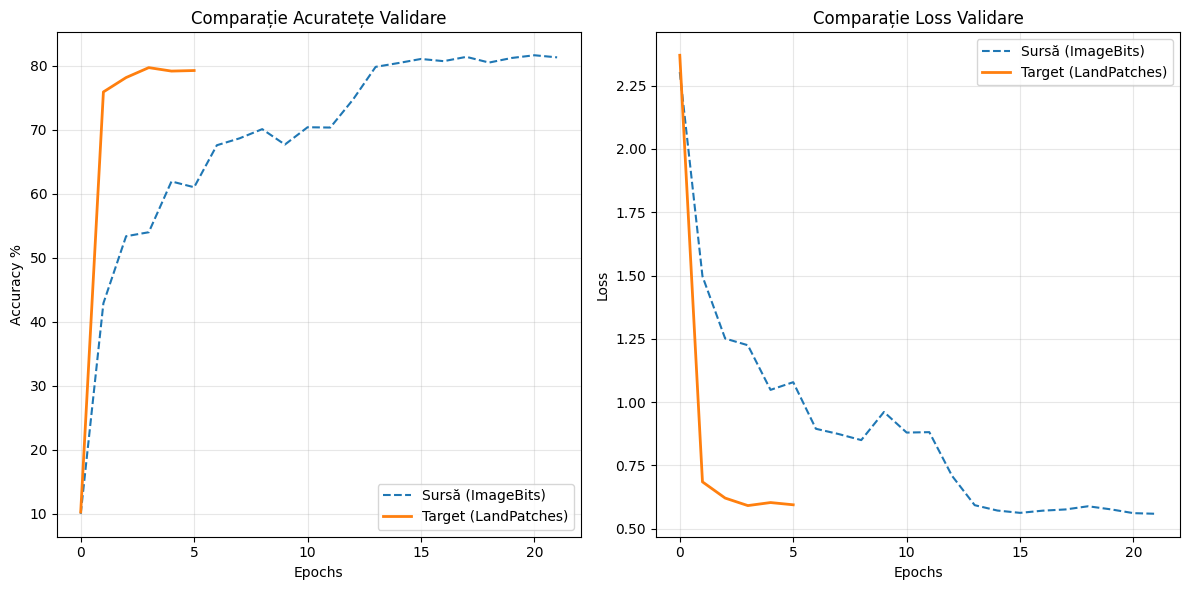


Final Result on LandPatches: 79.24% Accuracy


In [ ]:
import copy
import torch
import torch.nn as nn
import torch.optim as optim
import matplotlib.pyplot as plt

source_config = {
    "input": 512,
    "hidden1": 1024,
    "hidden2": 512,
    "batch_norm": True,
    "dropout_val": 0.5
}

source_net = MiniVGG(num_classes=10, in_size=source_config['input'], hidden_size1=source_config['hidden1'], hidden_size2=source_config['hidden2'], use_batch_norm=source_config['batch_norm'],dropout_val=source_config['dropout_val']).to(device)
optimizer_source = optim.Adam(source_net.parameters(), lr=0.0001, weight_decay=0.001)
scheduler_source = optim.lr_scheduler.MultiStepLR(optimizer_source, milestones=[20, 30], gamma=0.1)

hist_source = train_engine(net=source_net, train_data_loader=train_loader_aug, optimizer=optimizer_source,
                           scheduler=scheduler_source, num_epochs=35, name="Source_ImageBits_Training")

best_source_weights = copy.deepcopy(source_net.state_dict())
target_net = MiniVGG(num_classes=10, in_size=source_config['input'], hidden_size1=source_config['hidden1'],
                     hidden_size2=source_config['hidden2'], use_batch_norm=source_config['batch_norm'],
                     dropout_val=source_config['dropout_val']).to(device)

target_net.load_state_dict(best_source_weights)
for name, param in target_net.named_parameters():
    if "fc" not in name:
        param.requires_grad = False

num_ftrs = target_net.fc3.in_features
target_net.fc3 = nn.Linear(num_ftrs, 10).to(device)

params_to_update = [p for p in target_net.parameters() if p.requires_grad]

optimizer_target = optim.Adam(params_to_update, lr=0.0001, weight_decay=0.001)
scheduler_target = optim.lr_scheduler.MultiStepLR(optimizer_target, milestones=[10, 15], gamma=0.1)

hist_transfer = train_engine_land(net=target_net, train_data_loader=train_land_loader, val_data_loader=test_land_loader,
                                  optimizer=optimizer_target, scheduler=scheduler_target, num_epochs=35,
                                  name="Test")

plt.figure(figsize=(12, 6))

plt.subplot(1, 2, 1)
plt.plot(hist_source['val_acc'], label='Sursă (ImageBits)', linestyle='--')
plt.plot(hist_transfer['val_acc'], label='Target (LandPatches)', linewidth=2)
plt.title("Accuracy graph Test")
plt.xlabel("Epochs")
plt.ylabel("Accuracy %")
plt.legend()
plt.grid(True, alpha=0.3)

plt.subplot(1, 2, 2)
plt.plot(hist_source['val_loss'], label='Sursă (ImageBits)', linestyle='--')
plt.plot(hist_transfer['val_loss'], label='Target (LandPatches)', linewidth=2)
plt.title("Loss graph Test")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.legend()
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

all_preds = []
all_labels = []

target_net.eval()
with torch.no_grad():
    for images, labels in test_land_loader:
        images = images.to(device)
        outputs = target_net(images)
        _, predicted = torch.max(outputs, 1)

        all_preds.extend(predicted.cpu().numpy())
        all_labels.extend(labels.numpy())

cm = confusion_matrix(all_labels, all_preds)

plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False)
plt.title("Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("True")
plt.show()

print(f"\nFinal Result on LandPatches: {hist_transfer['val_acc'][-1]:.2f}% Accuracy")